<a href="https://colab.research.google.com/github/JuJo-SC/Juan-Jose-Santiago-Cruz-de-Algoritmos/blob/tarea/Juan_Jos%C3%A9_Santiago_Cruz_An%C3%A1lisis_de_Algoritmos_laboratorio_divide_y_venceras_unificado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Guía de Práctica de Laboratorio: Análisis Empírico y Estructural de Algoritmos Divide y Vencerás

**Asignatura:** Análisis de Algoritmos  
**Institución:** Universidad Autónoma de Tamaulipas (Facultad de Ingeniería Tampico)  
**Unidades / Subtemas:** Unidad 2 — Subtema 2.1 (Fundamentos: MinMax y Potencia) y Subtema 2.2 (Algoritmos Clásicos de Ordenamiento: MergeSort y QuickSort)  

**Objetivos de la Práctica:**
1. **Fundamentar teóricamente el paradigma:** Comprender las fases estructurales (Dividir, Conquistar y Combinar), el planteamiento de ecuaciones de recurrencia $T(n) = aT(n/b) + f(n)$ y sus cotas asintóticas mediante consultas guiadas en NotebookLM.
2. **Contrastar estructura visual frente a ejecución real:** Evaluar la topología recursiva (mediante árboles binarios jerárquicos en Python/NetworkX) frente al comportamiento de ejecución real a nivel de hardware (mediante medición de tiempos con `timeit` en Python y `chrono` con optimización `-O3` en C++).
3. **Analizar el compromiso tiempo-espacio y las estrategias de partición:** Comparar algoritmos de *división fácil y combinación difícil* (MergeSort, estable con espacio auxiliar $O(n)$) frente a algoritmos de *división difícil y combinación trivial* (QuickSort *in-place*), verificando el impacto de la selección de pivote (primer elemento vs. Mediana de Tres) y la eliminación de recursión de cola en la profundidad de la pila de llamadas.

---

## Introducción teórica y contexto

Divide y Vencerás resuelve una instancia al dividirla en subproblemas más pequeños, conquistar cada uno de forma recursiva y combinar sus resultados. El caso base se resuelve directamente. Cuando hay $a$ subproblemas de tamaño aproximadamente $n/b$ y el trabajo fuera de las llamadas es $f(n)$, se obtiene $T(n)=aT(n/b)+f(n)$. Los tamaños reales pueden requerir piso y techo. Si dependen del resultado de una partición, como en QuickSort, se modelan por separado.

- **MinMax:** divide por índice, obtiene los extremos de cada mitad y compara dos mínimos y dos máximos. Tiene casos base de uno y dos elementos, trabajo $\Theta(n)$ y pila $\Theta(\log n)$.
- **Potencia:** calcula una única subpotencia para el exponente $\lfloor n/2\rfloor$ y la reutiliza. Realiza $\Theta(\log n)$ multiplicaciones para $n\ge2$.
- **MergeSort:** divide por índice y dedica trabajo lineal a mezclar. Las versiones de la práctica tienen tiempo $\Theta(n\log n)$ y requieren $\Theta(n)$ de memoria auxiliar. El desempate a favor de la izquierda conserva la estabilidad del ordenamiento.
- **QuickSort:** dedica trabajo lineal a particionar por una clave pivote. Tiene tiempo $\Theta(n\log n)$ con particiones balanceadas y $\Theta(n^2)$ en el peor caso. En C++ se particiona dentro del arreglo. La mediana de tres reduce el riesgo de elegir un extremo en determinadas entradas. La garantía de pila $O(\log n)$ se obtiene con la llamada recursiva en el tramo pequeño y un ciclo sobre el grande.

Los diagramas en Python muestran las llamadas sin participar en las mediciones. Python usa `timeit` y C++ usa `std::chrono::steady_clock` con compilación `-O3`. La bitácora registra un conjunto verificable de corridas y contrasta sus resultados con el análisis teórico.


# Sección 1: Fundamentos de Divide y Vencerás — MinMax y Potencia (Subtema 2.1)

### 1.1 Guía de Autoestudio para NotebookLM (Tutor Cognitivo)

Copia y pega directamente las siguientes preguntas (*prompts*) en tu instancia de **NotebookLM**, consultando las fuentes oficiales cargadas en el notebook del curso para verificar y profundizar la precisión técnica del paradigma. <u>Tanto las preguntas como las respuestas obtenidas por la IA de NotebookLM deben transcribirse al portafolio de evidencias como notas de clase.</u>

#### Objetivo Temático 1: Comprender las Fases Estructurales e Identificación del Paradigma
* **Nivel Básico (Reconocimiento de conceptos):**
  > *"Basándote en el Capítulo IV de Gómez Fuentes & Cervantes Ojeda (UAM) y el Capítulo 4 de Baase & Van Gelder, describe con tus propias palabras cuáles son las tres fases formales del paradigma Divide y Vencerás (Dividir, Conquistar y Combinar) y qué ocurre cuando se alcanza el caso base."*
* **Nivel Intermedio (Análisis procedimental):**
  > *"A partir del texto de Lee et al. (Capítulo 4, Sección 4-1), explica paso a paso cómo se aplican las fases de Dividir, Conquistar y Combinar en el algoritmo de Búsqueda Simultánea de Mínimo y Máximo (MinMax). Detalla cuántas comparaciones exactas ahorra en comparación con el método iterativo lineal."*
* **Nivel Avanzado (Evaluación crítica y límites):**
  > *"Con base en las lecturas de la Antología UAM y el manual de la Universidad del Quindío, analiza cuál es la condición esencial respecto a la independencia de los subproblemas. ¿Por qué el algoritmo ingenuo de Fibonacci falla en ser eficiente al aplicar Divide y Vencerás y qué paradigma debe sustituirlo?"*

#### Objetivo Temático 2: Formulación Matemática y Ecuación de Recurrencia General
* **Nivel Básico (Reconocimiento de términos):**
  > *"De acuerdo con la Sección 6.7 del Manual de INACAP y la Sección 4.3 de Baase & Van Gelder, transcribe la ecuación de recurrencia general T(n) = aT(n/b) + f(n) y define qué representa cada uno de los parámetros: 'a', 'b' y 'f(n)'."*
* **Nivel Intermedio (Cálculo algebraico):**
  > *"Consulta el ejemplo del cálculo de la Potencia Recursiva x^n en el libro de la Universidad del Quindío (Capítulo 2, Sección 2.2). Explica la regla matemática para exponentes pares e impares y deriva por qué su complejidad temporal es O(log n) en lugar de O(n)."*
* **Nivel Avanzado (Rigor formal y derivación de cotas):**
  > *"Utilizando las fuentes del curso (Cormen et al. y Baase & Van Gelder), justifica cómo influye el costo de la función de combinación f(n) en el resultado final del Teorema Maestro. Proporciona un escenario donde un costo f(n) muy elevado domine la complejidad del algoritmo anulando la división."*

---

### Evidencia de NotebookLM · Subtema 2.1

Consultas ejecutadas con las fuentes del curso. El análisis revisado corrige las imprecisiones que aparecen en el historial de respuestas. [Cuaderno del curso en NotebookLM](https://notebook.google.com/notebook/5add46bb-4aed-47db-bacb-1287c3f6b657)

#### Consultas de la guía

**1.1** "Basándote en el Capítulo IV de Gómez Fuentes & Cervantes Ojeda (UAM) y el Capítulo 4 de Baase & Van Gelder, describe con tus propias palabras cuáles son las tres fases formales del paradigma Divide y Vencerás (Dividir, Conquistar y Combinar) y qué ocurre cuando se alcanza el caso base."

**1.2** "A partir del texto de Lee et al. (Capítulo 4, Sección 4-1), explica paso a paso cómo se aplican las fases de Dividir, Conquistar y Combinar en el algoritmo de Búsqueda Simultánea de Mínimo y Máximo (MinMax). Detalla cuántas comparaciones exactas ahorra en comparación con el método iterativo lineal."

**1.3** "Con base en las lecturas de la Antología UAM y el manual de la Universidad del Quindío, analiza cuál es la condición esencial respecto a la independencia de los subproblemas. ¿Por qué el algoritmo ingenuo de Fibonacci falla en ser eficiente al aplicar Divide y Vencerás y qué paradigma debe sustituirlo?"

**1.4** "De acuerdo con la Sección 6.7 del Manual de INACAP y la Sección 4.3 de Baase & Van Gelder, transcribe la ecuación de recurrencia general T(n) = aT(n/b) + f(n) y define qué representa cada uno de los parámetros: 'a', 'b' y 'f(n)'."

**1.5** "Consulta el ejemplo del cálculo de la Potencia Recursiva x^n en el libro de la Universidad del Quindío (Capítulo 2, Sección 2.2). Explica la regla matemática para exponentes pares e impares y deriva por qué su complejidad temporal es O(log n) en lugar de O(n)."

**1.6** "Utilizando las fuentes del curso (Cormen et al. y Baase & Van Gelder), justifica cómo influye el costo de la función de combinación f(n) en el resultado final del Teorema Maestro. Proporciona un escenario donde un costo f(n) muy elevado domine la complejidad del algoritmo anulando la división."

#### Respuestas revisadas

1. **Fases y caso base.** Dividir transforma una instancia en instancias menores del mismo problema. Conquistar resuelve cada una mediante el mismo procedimiento y combinar reconstruye la solución de la instancia original. La corrección se prueba por inducción sobre el tamaño. En los casos base se verifica la solución directa. En el paso inductivo se supone la corrección de los hijos, cuyo tamaño debe ser estrictamente menor, y se demuestra que la combinación produce la solución del padre. Por ejemplo, combinar los mínimos de dos mitades da el mínimo global porque cada elemento pertenece a una de ellas.

2. **MinMax y ahorro.** Se parte por índices. Cada hoja de tamaño 1 cuesta cero comparaciones y cada hoja de tamaño 2 cuesta una. La combinación cuesta dos. Para $n>2$, $C(n)=C(\lceil n/2\rceil)+C(\lfloor n/2\rfloor)+2$. Si $n=2^k$ con $k\ge1$, hay $n/2$ hojas de tamaño 2 y $n/2-1$ nodos internos. Así, $C(n)=3n/2-2$, un ahorro de $n/2$ frente a $2n-2$ en el peor caso del recorrido con dos posibles comparaciones por elemento. La reducción porcentual para ese caso es $100(n/2)/(2n-2)$ y se aproxima a 25 %. Para tamaños arbitrarios, si hay $s$ hojas unitarias y $p$ hojas pares, $C(n)=p+2(s+p-1)=(3n+s)/2-2$. Por ejemplo, $n=6$ produce dos hojas unitarias y dos pares y cuesta 8 comparaciones. La cota de $\lceil3n/2\rceil-2$ se alcanza con MinMax por parejas, que maximiza el número de pares. La versión iterativa concreta comprueba primero el mínimo con un `elif` para el máximo. En entradas descendentes hace $n$ comparaciones para $n\ge2$, pues sus primeras dos comparaciones inicializan ambos extremos. Su peor caso, por ejemplo en una entrada ascendente, hace $2n-2$. Dos recorridos independientes completos también hacen $2n-2$. NotebookLM señala que Lee et al. §4-1 trata el caso geométrico bidimensional y remite a Baase §5.2 y Cormen §9.1 para el conteo de MinMax.

3. **Solapamiento y Fibonacci.** Los subproblemas se pueden resolver sin depender de resultados aún desconocidos de sus hermanos. El solapamiento relevante es que la misma instancia se vuelva a resolver desde varias ramas. Con $F(0)=0$, $F(1)=1$, al calcular $F(n)$, la rama $F(n-1)$ vuelve a solicitar $F(n-2)$, ya solicitado por la otra rama. La recurrencia de trabajo $W(n)=W(n-1)+W(n-2)+\Theta(1)$ produce $\Theta(\varphi^n)$ llamadas para $\varphi=(1+\sqrt5)/2$. La programación dinámica con memoización resuelve $n+1$ estados una vez cada uno, en $\Theta(n)$ sumas y $\Theta(n)$ espacio. El método ascendente que conserva dos términos usa $\Theta(1)$ espacio auxiliar en el modelo de costo unitario.

4. **Recurrencia general.** Para $n=b^k$, caso base $T(1)=\Theta(1)$, $a\ge1$ entero y factor constante $b>1$, el trabajo recursivo de $a$ hijos cuesta $aT(n/b)$ y el trabajo local cuesta $f(n)$, incluyendo división, preparación y combinación. Así $T(n)=aT(n/b)+f(n)$ y, al expandir $k$ niveles, $T(n)=a^kT(1)+\sum_{i=0}^{k-1}a^i f(n/b^i)$. El término $a^k=n^{\log_b a}$ cuenta las hojas. Para tamaños no exactos se modela con pisos y techos y se comprueban las hipótesis del teorema que se aplique.

5. **Potencias pares e impares.** Para $n\ge1$, se calcula una vez $y=x^{\lfloor n/2\rfloor}$. Si $n=2q$ se devuelve $y^2$. Si $n=2q+1$ se devuelve $x y^2$. El caso base es $x^0=1$. Con multiplicaciones de ancho fijo y resultados representables, $T(n)=T(\lfloor n/2\rfloor)+\Theta(1)$ y se llega a 0 tras $\lfloor\log_2 n\rfloor+1$ divisiones. Esto da $\Theta(\log n)$ tiempo para $n\ge2$. La multiplicación repetida cuesta $\Theta(n)$. Si los enteros crecen en longitud, se debe considerar el costo de cada multiplicación.

6. **Teorema Maestro.** Con $d=\log_b a$, si $f(n)=O(n^{d-\varepsilon})$ para algún $\varepsilon>0$, dominan las hojas y $T(n)=\Theta(n^d)$. Si $f(n)=\Theta(n^d)$, cada nivel tiene trabajo del mismo orden y $T(n)=\Theta(n^d\log n)$. Si $f(n)=\Omega(n^{d+\varepsilon})$ y se cumple la regularidad $a f(n/b)\le c f(n)$ para una constante $c<1$ y $n$ suficientemente grande, domina el trabajo local y $T(n)=\Theta(f(n))$. En $T(n)=2T(n/2)+n^2$, el nivel $i$ cuesta $n^2/2^i$. La suma geométrica cuesta $\Theta(n^2)$, de modo que una combinación cuadrática conserva el orden cuadrático del costo global.


#### Transcripción de NotebookLM

<details>
<summary>Consultas 1.1 a 1.3</summary>

**1.1 Fases formales de Divide y Vencerás y comportamiento en el caso base**

De acuerdo con el Capítulo IV de **Gómez Fuentes & Cervantes Ojeda (UAM)** y el Capítulo 4 (Sección 4.3) de **Baase & Van Gelder**, el paradigma de **Divide y Vencerás** descompone una instancia compleja en problemas más pequeños de la misma naturaleza, los resuelve recursivamente y luego ensambla sus resultados [1]. Formalmente, este diseño opera en **tres fases continuas**:

1. **Dividir (Divide):**
   Consiste en fragmentar la entrada original de tamaño $n$ en $k$ subproblemas más pequeños ($I_1, I_2, \dots, I_k$), donde idealmente cada subproblema posee un tamaño balanceado o fraccionario respecto al original (por ejemplo, de tamaño $n/2$ o $n/c$) [4]. Esta partición se realiza mediante operaciones preliminares cuyo costo temporal no recursivo se denota habitualmente como $D(n)$ o parte de $f(n)$ [5] [7].
2. **Conquistar o Vencer (Conquer):**
   Los subproblemas generados se resuelven de forma **recursiva** aplicando exactamente el mismo algoritmo [1]. Si la división produjo ejemplares que aún no son lo suficientemente sencillos, el algoritmo vuelve a dividirlos en una cascada de llamadas que desciende a través de los distintos niveles de profundidad [2] [10].
3. **Combinar (Combine):**
   Una vez obtenidas las soluciones particulares de cada uno de los subproblemas ($S_1, S_2, \dots, S_k$), estas se ensamblan o fusionan mediante un procedimiento específico (con costo no recursivo $C(n)$) para dar origen a la solución final del problema global original [1].

**¿Qué ocurre cuando se alcanza el caso base?**

Tanto Gómez Fuentes & Cervantes Ojeda como Baase & Van Gelder establecen que la subdivisión no puede repetirse indefinidamente [2]. Para **escapar de la recursión**, se define un **tamaño umbral** ($n_0$ o condición de tamaño pequeño) [7].

Cuando el tamaño de un subproblema es menor o igual a este umbral ($n \le n_0$), la recursión se detiene de inmediato [8] [11]:

- **No se generan más subdivisiones ni llamadas recursivas adicionales** [7] [8].
- El subproblema se resuelve directamente invocando un algoritmo básico elemental (`resolverDirectamente(I)` o función $g(n)$) en **tiempo constante **$O(1)$ o con un costo computacional predefinido y mínimo ($B(n)$), permitiendo que comience el ascenso y la combinación de resultados [5].

---

**1.2 Búsqueda Simultánea de Mínimo y Máximo (MinMax) y ahorro de comparaciones**

**Aclaración sobre la literatura de Lee et al.:**

En el texto de **Lee et al.** (Introducción al diseño y análisis de algoritmos), el Capítulo 4 introduce Divide y Vencerás ilustrando en sus páginas iniciales (119–121) la búsqueda de **un único máximo** global [10] [12]. La **Sección 4-1** de Lee et al. está dedicada específicamente al problema geométrico de **"Puntos máximos en un espacio bidimensional"** (determinación de puntos no dominados o frontera de Pareto en el plano) [13].

La formulación canónica de **Búsqueda Simultánea de Mínimo y Máximo (MinMax)** mediante Divide y Vencerás —así como el conteo formal de comparaciones frente al método iterativo— se encuentra desarrollada en las fuentes complementarias del curso, principalmente en **Baase & Van Gelder (Capítulo 5, Sección 5.2)** y **Cormen et al. (Capítulo 9, Sección 9.1)** [14] [15].

---

**A. Aplicación de las tres fases en MinMax (Divide y Vencerás)**

Para un arreglo $A$ de $n$ elementos:

- **Fase 1: Dividir:**
   Si $n > 2$, se calcula el índice intermedio $\lfloor n/2 \rfloor$ y el arreglo se parte en dos mitades contiguas: $A_{\text{izq}} = A[1 \dots \lfloor n/2 \rfloor]$ y $A_{\text{der}} = A[\lfloor n/2 \rfloor + 1 \dots n]$. Este paso requiere únicamente aritmética de índices y **no efectúa ninguna comparación entre elementos** ($D(n) = 0$).
- **Fase 2: Conquistar:**
   Se ejecutan dos llamadas recursivas independientes:
   $$\text{MinMax}(A_{\text{izq}}) \longrightarrow (\min_1, \max_1)$$
    
   $$\text{MinMax}(A_{\text{der}}) \longrightarrow (\min_2, \max_2)$$
    Cuando una partición llega a los **casos base**, se resuelve directamente:- Si el subarreglo tiene **1 solo elemento** ($n = 1$): $\min = \max = A$ [16] (**0 comparaciones**).
   - Si el subarreglo tiene **2 elementos** ($n = 2$): se comparan entre sí (**1 comparación**); el menor es el $\min$ local y el mayor es el $\max$ local.
- **Fase 3: Combinar:**
   Con las dos parejas de soluciones locales $(\min_1, \max_1)$ y $(\min_2, \max_2)$, se efectúan exactamente **2 comparaciones**:1. $\min_1$ contra $\min_2$ para determinar el mínimo global: $\min_{\text{global}} = \min(\min_1, \min_2)$.
   2. $\max_1$ contra $\max_2$ para determinar el máximo global: $\max_{\text{global}} = \max(\max_1, \max_2)$.
      Costo de combinación: $C(n) = 2$ comparaciones.

---

**B. Derivación analítica de comparaciones**

Suponiendo una entrada de tamaño potencia de 2 ($n = 2^k$ con $k \ge 1$), la recurrencia para el conteo de comparaciones $T(n)$ es:
$$T(n) = 2T(n/2) + 2 \quad \text{con caso base } T(2) = 1$$

Resolviendo mediante expansión hacia atrás (sustitución iterativa):
$$T(n) = 2T(n/2) + 2$$

$$T(n) = 2[2T(n/4) + 2] + 2 = 4T(n/4) + 4 + 2$$

$$T(n) = 2^j T(n/2^j) + \sum_{i=1}^{j} 2^i$$

La recursión se detiene cuando el tamaño del subproblema alcanza el caso base $n/2^j = 2$, lo que ocurre tras $j = k - 1$ niveles de división:
$$T(n) = 2^{k-1} T(2) + \sum_{i=1}^{k-1} 2^i$$

Sabiendo que $T(2) = 1$ y que $\sum_{i=1}^{k-1} 2^i = 2^k - 2$:
$$T(n) = 2^{k-1}(1) + (2^k - 2)$$
 Sustituyendo $2^k = n$ y $2^{k-1} = n/2$:
$$T(n) = \frac{n}{2} + n - 2 = \mathbf{\frac{3n}{2} - 2}$$

(Para un $n$ arbitrario, la literatura formal de Baase y Cormen generaliza este costo en $\lceil 3n/2 \rceil - 2$ comparaciones [14]).

---

**C. Comparativa y ahorro exacto frente al método iterativo lineal**

En el **algoritmo iterativo clásico** (recorriendo el arreglo de forma secuencial):

1. Se inicializan el mínimo y el máximo con el primer elemento ($A$ [16]) [17].
2. Por cada uno de los $n - 1$ elementos restantes, en el **peor caso** (por ejemplo, si el arreglo está en orden estrictamente decreciente) se debe comparar el elemento contra el máximo actual y, al fallar, contra el mínimo actual [14] [17].
3. Costo del método iterativo en el peor caso:
   $$T_{\text{iterativo}}(n) = 2(n - 1) = \mathbf{2n - 2 \text{ comparaciones}}$$
    (Si se buscaran el máximo y el mínimo en dos pasadas independientes, se requerirían $(n - 1) + (n - 2) = 2n - 3$ comparaciones [14]).

**Diferencia y ahorro exacto:**
$$\Delta = T_{\text{iterativo}} - T_{\text{DyV}} = (2n - 2) - \left(\frac{3n}{2} - 2\right) = \mathbf{\frac{n}{2} \text{ comparaciones}}$$

- **Conclusión de rendimiento:** El enfoque de Divide y Vencerás ahorra exactamente $n/2$** comparaciones** en el peor caso respecto al algoritmo lineal de exploración directa, lo cual representa una reducción exacta del **25%** del trabajo computacional [14].

---

**1.3 Condición de independencia de los subproblemas y el caso de Fibonacci**

**A. La condición esencial de independencia**

Tanto la **Antología de la UAM (Gómez Fuentes et al.)** como el manual de la **Universidad del Quindío** establecen de forma terminante que la condición crítica para la viabilidad de Divide y Vencerás es la **independencia estricta de los subproblemas** [18]:

- **No debe existir traslape ni solapamiento:** Cada subproblema en el que se fragmenta la entrada debe ser disjunto y resolverse de manera aislada sin compartir datos intermedios con las otras ramas [18].
- **Impacto del solapamiento:** Si se intenta aplicar Divide y Vencerás a problemas donde los subproblemas comparten cálculos, el algoritmo recalculará las mismas soluciones parciales una y otra vez a través de las ramas del árbol de activación, provocando una **explosión combinatoria que eleva el tiempo de ejecución a un orden exponencial** ($O(2^n)$ o $O(b^n)$) [18].

---

**B. ¿Por qué falla el algoritmo ingenuo de Fibonacci con Divide y Vencerás?**

La relación matemática de Fibonacci está definida por:
$$\text{Fib}(n) = \text{Fib}(n - 1) + \text{Fib}(n - 2) \quad \text{con } \text{Fib}(0) = 1, \text{Fib}(1) = 1 \text{ (o base 0, 1)}$$
 [24]

Al aplicar una estrategia recursiva pura tipo Divide y Vencerás:

1. **Falta total de independencia:** Para calcular $\text{Fib}(n)$, el algoritmo se ramifica en $\text{Fib}(n-1)$ y $\text{Fib}(n-2)$ [24] [25]. A su vez, la rama de $\text{Fib}(n-1)$ necesita calcular $\text{Fib}(n-2)$ y $\text{Fib}(n-3)$ [25].
2. **Duplicación masiva de llamadas:** El valor de $\text{Fib}(n-2)$ se calcula dos veces de forma totalmente aislada; $\text{Fib}(n-3)$ se calculará tres veces, y los términos inferiores se recomputan millones de veces en subárboles idénticos e inconexos [23].
3. **Degradación asintótica:** Debido a la carencia de independencia y al solapamiento masivo, la cantidad de operaciones elementales crece de forma proporcional a la secuencia de Fibonacci misma, derivando en una **complejidad temporal exponencial **$O(2^n)$ (específicamente $\Theta(\phi^n)$, donde $\phi \approx 1.618$) [24].

---

**C. Paradigma sustituto: Programación Dinámica**

El paradigma que debe sustituir a Divide y Vencerás cuando existe solapamiento de subproblemas es la **Programación Dinámica (PD)** [18].

- **Principio rector:** La Programación Dinámica se rige por la premisa de **"no calcular dos veces lo mismo"** y se apoya en el Principio de Optimalidad de Bellman [20].
- **Mecanismo:** En lugar de bifurcarse recursivamente a ciegas, la Programación Dinámica resuelve cada subproblema **una sola vez** y almacena su resultado en una tabla o arreglo auxiliar (mediante memorización descendente o construcción iterativa ascendente bottom-up) [20].
- **Resultado en Fibonacci:** Al reutilizar los valores previos ya tabulados ($\text{Fib}[i] = \text{Fib}[i-1] + \text{Fib}[i-2]$), el cálculo del $n$-ésimo número de Fibonacci se reduce drásticamente de un tiempo exponencial $O(2^n)$ a un **tiempo lineal eficiente de **$O(n)$ [25].

---

📊 Si lo requieres para la entrega del reporte, podemos generar una tabla comparativa de los órdenes de complejidad de los casos analizados o plasmar estos árboles de llamadas en un diagrama formal.

**Referencias visibles en esta respuesta**

- [1, 4, 5, 8, 14] Algoritmos_Computacionales_Baase_3ra.pdf
- [7, 2, 11, 18, 24, 23] Notas_Analisis_AlgoritmosVF.pdf
- [10, 12, 13] introduccion-al-diseno-y-analisis-de-algoritmos-lee-tseng-chang-y-tsai.pdf
- [15] Introduction_to_algorithms-3rd Edition.pdf
- [16] 2873588-Analisis de algoritmos-Antologia.pdf
- [17] Análisis y diseño de algoritmos - Gustavo López-FREELIBROS.ORG.pdf
- [25, 20] analisis-de-algoritmos-para-ingenieria-de-sistemas-y-computacion.pdf

</details>

<details>
<summary>Consultas 1.4 a 1.6</summary>

**1.4 Ecuación de recurrencia general de Divide y Vencerás y significado de sus parámetros**

De acuerdo con el **Manual de Análisis de Algoritmos de INACAP** [1] y el texto de **Baase & Van Gelder** [2], la ecuación de recurrencia canónica para algoritmos que siguen la estrategia de Divide y Vencerás se expresa formalmente como:

$$T(n) = a T\left(\frac{n}{b}\right) + f(n)$$

(En la notación propia del libro de Baase & Van Gelder se formula de manera análoga como $T(n) = b T(n/c) + f(n)$, denominando $b$ al número de subproblemas y $c$ al factor de escala [2]).

En la formulación estándar establecida en las fuentes, cada componente representa [1]:

1. **Parámetro **$a$** (donde **$a \ge 1$**):**
   Representa la **cantidad de subproblemas** en los que se divide la instancia original de tamaño $n$ [1]. Cada uno de estos subproblemas se resuelve de forma recursiva independiente [2] [6]. En la literatura de Baase se denomina formalmente como el factor de ramificación [3].
2. **Parámetro **$b$** (donde **$b > 1$**):**
   Representa el **factor de reducción o escala** por el cual se divide el tamaño de la entrada en cada paso recursivo [1]. Cada llamada recursiva recibe una porción del problema cuyo tamaño es una fracción $n/b$ (interpretado formalmente con funciones piso $\lfloor n/b \rfloor$ o techo $\lceil n/b \rceil$) [1] [5].
3. **Término **$f(n)$**:**
   Corresponde al **costo no recursivo** del algoritmo para un tamaño de entrada $n$ [2] [3]. Engloba conjuntamente el esfuerzo computacional requerido para **dividir** el problema principal en subproblemas ($D(n)$) más el esfuerzo necesario para **combinar o fusionar** las soluciones parciales de los subproblemas y generar la solución definitiva ($C(n)$) [2].

---

**1.5 Potencia Recursiva $x^n$ (Universidad del Quindío): Reglas y derivación de $O(\log n)$ vs. $O(n)$**

En el texto Análisis de algoritmos para ingeniería de sistemas y computación de la **Universidad del Quindío** (Capítulo 2) [7], se expone el cálculo recursivo de la potencia $x^n$ distinguiendo entre una implementación ingenua y una optimizada mediante división balanceada [7].

**A. Regla matemática para exponentes pares e impares**

Para cualquier base $x$ y exponente natural $n \ge 0$, la potencia se apoya en la descomposición de potencias de exponente entero [7]:

- **Caso base:** Si $n = 0$, entonces $x^0 = 1$ [7].
- **Exponente par (**$n \pmod 2 = 0$**):**
   
   $$x^n = \left(x^{n/2}\right) \cdot \left(x^{n/2}\right) = \left(x^{n/2}\right)^2$$
- **Exponente impar (**$n \pmod 2 \neq 0$**):**
   
   $$x^n = \left(x^{n/2}\right) \cdot \left(x^{n/2}\right) \cdot x = \left(x^{n/2}\right)^2 \cdot x$$

---

**B. Derivación analítica: ¿Por qué la versión optimizada es $O(\log n)$ y no $O(n)$?**

El texto de la Universidad del Quindío enfatiza que la diferencia entre obtener un crecimiento lineal $O(n)$ o logarítmico $O(\log n)$ radica estrictamente en **evitar la duplicación de llamadas recursivas** [7]:

1. **El fallo de la versión no optimizada (**$O(n)$**):**
   Si el algoritmo evalúa la multiplicación invocando la función recursiva dos veces por separado (`calcularPotencia(x, n/2) * calcularPotencia(x, n/2)`) [7], se generan **dos llamadas de tamaño **$n/2$ [11]. La recurrencia resultante es [11]:
   $$T(n) = 2T(n/2) + b$$
    Aplicando expansión iterativa con caso base $T(1) = a$ [11]:
   $$T(2) = 2a + b$$
    
   $$T(4) = 4a + 3b$$
    
   $$T(8) = 8a + 7b$$
    $$T(n) = n \cdot a + (n - 1)b \implies \mathbf{T(n) \in O(n)} \text{$$ [11]$$.}$$ A pesar de dividir $n$ entre 2, el algoritmo degrada a complejidad lineal porque recomputa exactamente el mismo subproblema dos veces en cada nivel [11].
2. **La versión optimizada mediante variable auxiliar (**$O(\log n)$**):**
   En la implementación óptima analizada por la Universidad del Quindío, se calcula el subproblema **una sola vez** y se almacena en memoria (`int y = calcularPotencia(x, n/2); return y * y;`) [8] [9].- Dado que solo se ejecuta **una llamada recursiva** de tamaño $n/2$ y una multiplicación de costo constante $O(1)$, la recurrencia real es [9]: $$T(n) = T\left(\frac{n}{2}\right) + b \quad \text{con } T(1) = a \text{$$ [9]$$.}$$
   - Realizando la derivación por sustitución regresiva (asumiendo $n = 2^k$) [12] [13]:
      $$T(2) = T(1) + b = 1b + a$$
       
      $$T(4) = T(2) + b = 2b + a$$
       
      $$T(8) = T(4) + b = 3b + a$$
       
      $$T(2^k) = k \cdot b + a$$
   - Como $k = \log_2 n$, se obtiene la forma cerrada [12] [13]: $$T(n) = b \log_2(n) + a \implies \mathbf{T(n) \in O(\log n)} \text{$$ [12] [13]$$.}$$

---

**1.6 Influencia de la función de combinación $f(n)$ en el Teorema Maestro y escenario de anulación**

De acuerdo con el análisis formal de **Baase & Van Gelder (Sección 3.7 / Teorema 3.17)** [4] y **Cormen et al.** [1] [5], la complejidad asintótica de una recurrencia $T(n) = aT(n/b) + f(n)$ está determinada por una **competencia asintótica** entre dos fuerzas opuestas [4]:

1. El costo intrínseco de las **hojas del árbol de recursión**, el cual es de orden $\Theta(n^E)$, donde $E = \log_b a$ es el denominado **exponente crítico** [4] [14].
2. El costo no recursivo en la **raíz del árbol**, determinado por $f(n)$ (la partición y combinación) [15].

**A. Los tres escenarios de influencia de $f(n)$**

- **Caso 1 (Dominan las hojas):** Si $f(n) \in O(n^{\log_b a - \epsilon})$ para algún $\epsilon > 0$, el costo de combinación es despreciable frente al número de subproblemas elementales; el costo total está gobernado por las hojas: $T(n) \in \Theta(n^{\log_b a})$ [1].
- **Caso 2 (Equilibrio estricto):** Si $f(n) \in \Theta(n^{\log_b a})$, cada uno de los $\Theta(\log n)$ niveles del árbol de recursión acumula la misma cantidad de trabajo, resultando en $T(n) \in \Theta(n^{\log_b a} \lg n)$ [1].
- **Caso 3 (Domina la función de combinación):** Si $f(n) \in \Omega(n^{\log_b a + \epsilon})$ para algún $\epsilon > 0$ y cumple la condición de regularidad $a \cdot f(n/b) \le c \cdot f(n)$ con $c < 1$, los costos por nivel forman una serie geométrica decreciente donde el primer nivel domina totalmente la sumatoria [1]: $$T(n) \in \Theta(f(n)) \text{$$ [1]$$.}$$

---

**B. Escenario donde un costo $f(n)$ elevado domina y anula el beneficio de la división**

Consideremos un algoritmo que divide la entrada a la mitad en **dos subproblemas** ($a = 2, b = 2$), pero cuya fase de combinación requiere un procesamiento de complejidad cuadrática:
$$T(n) = 2T\left(\frac{n}{2}\right) + n^2$$

- **Cálculo del exponente crítico:**
   $$E = \log_b a = \log_2 2 = 1 \implies n^E = n^1 = n \text{$$ [4]$$.}$$
- **Comparación con **$f(n)$**:**
   Como $f(n) = n^2$, evaluamos el Caso 3 con $\epsilon = 1$ [5] [17]: $$f(n) = n^2 \in \Omega(n^{1 + 1}) = \Omega(n^2) \text{$$ [5] [17]$$.}$$
- **Verificación de la condición de regularidad:**
   
   $$a \cdot f\left(\frac{n}{b}\right) = 2 \cdot \left(\frac{n}{2}\right)^2 = 2 \cdot \frac{n^2}{4} = \frac{n^2}{2} = \frac{1}{2} f(n)$$
    Se cumple con una constante $c = 1/2 < 1$ [1] [5].

**Conclusión del escenario:**
Por el Caso 3 del Teorema Maestro, la complejidad resultante es: $$\mathbf{T(n) \in \Theta(n^2)} \text{$$ [1]$$.}$$

**Impacto algorítmico:** A pesar de haber partido el problema recurrentemente en mitades simétricas (lo que teóricamente permitiría cotas casi lineales como $O(n \log n)$), el esfuerzo cuadrático excesivo invertido en la raíz para combinar las respuestas anula por completo la ventaja de la división recursiva, haciendo que el algoritmo sea tan lento como una solución ingenua de bucles anidados [17].

---

💡 Si necesitas que pasemos a los siguientes puntos del laboratorio o prefieres graficar el árbol de costos de este último escenario para visualizar cómo decae la serie, me dices y lo preparamos de inmediato.

**Referencias visibles en esta respuesta**

- [1] manual-analisis-de-algoritmos.pdf
- [2, 3, 4, 14, 15, 17] Algoritmos_Computacionales_Baase_3ra.pdf
- [6, 7, 11, 8, 9, 12, 13] analisis-de-algoritmos-para-ingenieria-de-sistemas-y-computacion.pdf
- [5] AntologiaAnalisisAlg_26-1.pdf

</details>

### 1.2 Laboratorio en Python: Visualización Jerárquica y Benchmark (MinMax)

*Instrucciones:* Ejecuta esta celda en Google Colab. Observa cómo la función `plot_hierarchical_tree` organiza el árbol de llamadas de manera vertical y ordenada para facilitar su conteo e inspección topológica.

=== GENERANDO ÁRBOL DE RECURSIÓN JERÁRQUICO (DIVIDE Y VENCERÁS MINMAX) ===


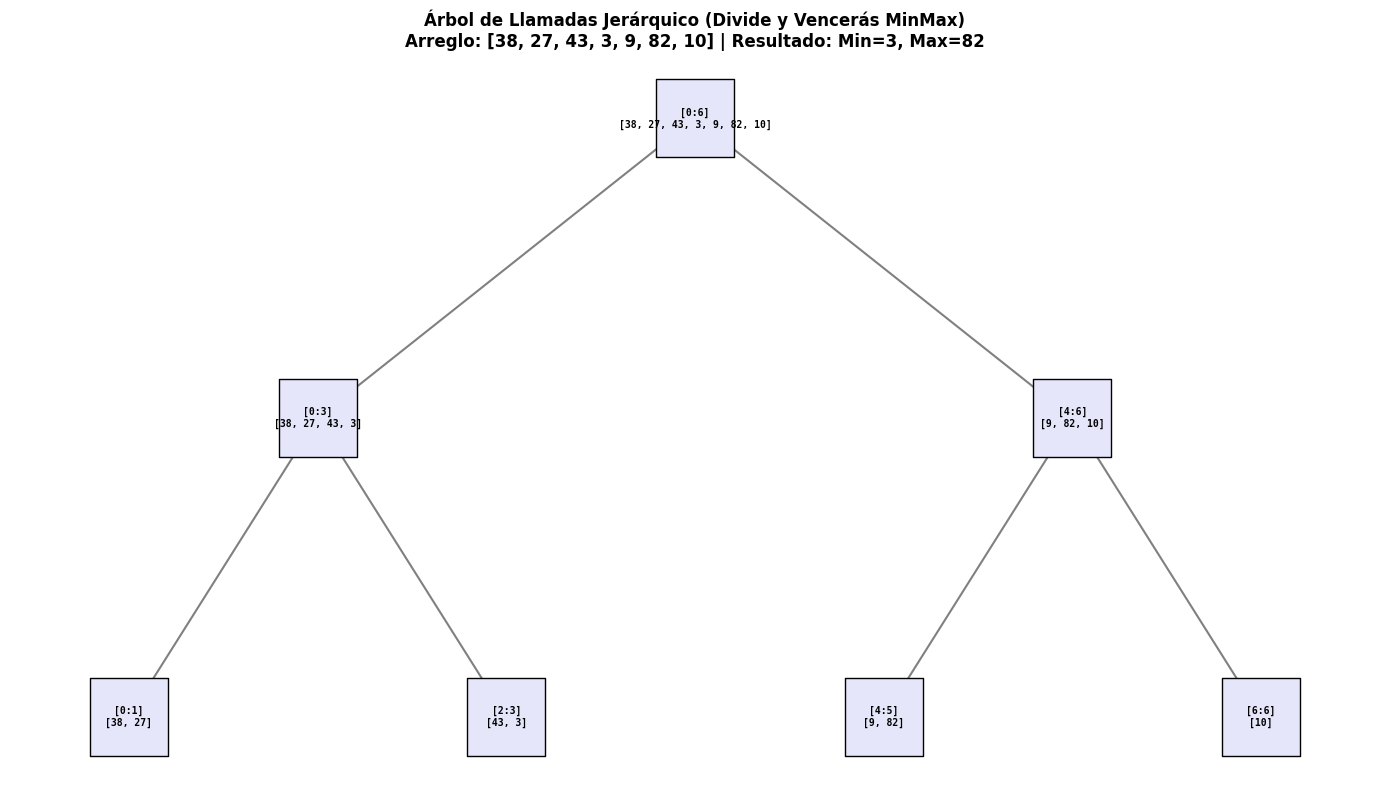


=== BENCHMARK DE RENDIMIENTO (D&C vs ITERATIVO) ===
Nodos por profundidad (raíz = 0): {0: 1, 1: 2, 2: 4}
Hojas por profundidad: {2: 4} | Total: 4
Python 3.13.18 | Linux x86_64
n = 10000 descendentes | 5 lotes de 10 ejecuciones por algoritmo
MinMax D&C: 13.901618 ms/ejecución (rango entre lotes: 9.877360–18.741084)
MinMax iterativo: 3.490095 ms/ejecución (rango entre lotes: 2.788604–4.917599)
Razón D&C / iterativo: 3.98×


In [ ]:
# ==============================================================================
# LABORATORIO UNIDAD 2 - DIVIDE Y VENCERÁS EN PYTHON
# ==============================================================================
import timeit
import platform
from collections import Counter
import matplotlib.pyplot as plt
import networkx as nx

# ------------------------------------------------------------------------------
# 1. ALGORITMO MODELO I: BÚSQUEDA SIMULTÁNEA DE MÍNIMO Y MÁXIMO (DIVIDE Y VENCERÁS)
# ------------------------------------------------------------------------------
def minmax_divide_conquer(arr, low, high, tree_graph=None, parent_id=None):
    """
    Encuentra el mínimo y máximo de forma recursiva construyendo el árbol de llamadas.
    """
    if high < low:
        raise ValueError("MinMax requiere al menos un elemento")
    node_id = None
    if tree_graph is not None:
        node_id = (low, high)
        label = f"[{low}:{high}]\n{arr[low:high+1]}"
        tree_graph.add_node(node_id, label=label)
        if parent_id is not None:
            tree_graph.add_edge(parent_id, node_id)

    # Caso Base 1: Un solo elemento
    if low == high:
        return (arr[low], arr[low])

    # Caso Base 2: Dos elementos
    if high == low + 1:
        if arr[low] < arr[high]:
            return (arr[low], arr[high])
        else:
            return (arr[high], arr[low])

    # FASE 1: DIVIDIR
    mid = (low + high) // 2

    # FASE 2: CONQUISTAR (Recursión)
    min1, max1 = minmax_divide_conquer(arr, low, mid, tree_graph, node_id)
    min2, max2 = minmax_divide_conquer(arr, mid + 1, high, tree_graph, node_id)

    # FASE 3: COMBINAR (2 comparaciones finales)
    global_min = min1 if min1 < min2 else min2
    global_max = max1 if max1 > max2 else max2

    return (global_min, global_max)

# ------------------------------------------------------------------------------
# 2. ALGORITMO ITERATIVO ESTÁNDAR (PARA COMPARACIÓN BENCHMARK)
# ------------------------------------------------------------------------------
def minmax_iterative(arr):
    n = len(arr)
    if n == 0:
        raise ValueError("MinMax requiere al menos un elemento")
    if n == 1:
        return (arr[0], arr[0])

    g_min = min(arr[0], arr[1])
    g_max = max(arr[0], arr[1])

    for i in range(2, n):
        if arr[i] < g_min:
            g_min = arr[i]
        elif arr[i] > g_max:
            g_max = arr[i]

    return (g_min, g_max)

# ------------------------------------------------------------------------------
# 3. VISUALIZACIÓN JERÁRQUICA LIMPIA DEL ÁRBOL DE RECURSIÓN (REUTILIZABLE)
# ------------------------------------------------------------------------------
def plot_hierarchical_tree(G, root_id, title, node_color='lavender', labels=None):
    """
    Dibuja un grafo de NetworkX con una disposición jerárquica de árbol binario exacto,
    sin requerir Graphviz externo.
    """
    pos = {}

    def t_pos(node, x_center, y_top, width, level_height):
        pos[node] = (x_center, y_top)
        neighbors = list(G.successors(node))
        if not neighbors:
            return
        # Los hijos se insertan en el grafo de izquierda a derecha.

        # Hijo izquierdo
        t_pos(neighbors[0], x_center - width/2, y_top - level_height, width/2, level_height)
        # Hijo derecho (si existe)
        if len(neighbors) > 1:
            t_pos(neighbors[1], x_center + width/2, y_top - level_height, width/2, level_height)

    t_pos(root_id, x_center=0.5, y_top=1.0, width=0.6, level_height=0.15)

    plt.figure(figsize=(14, 8))
    if labels is None:
        labels = nx.get_node_attributes(G, "label")

    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15, width=1.5)
    nx.draw_networkx_nodes(G, pos, node_color=node_color, node_size=3200, edgecolors='black', node_shape='s')
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=7, font_weight='bold', font_family='monospace')

    plt.title(title, fontsize=12, fontweight='bold')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

print("=== GENERANDO ÁRBOL DE RECURSIÓN JERÁRQUICO (DIVIDE Y VENCERÁS MINMAX) ===")
G = nx.DiGraph()
sample_array = [38, 27, 43, 3, 9, 82, 10]
res_min, res_max = minmax_divide_conquer(sample_array, 0, len(sample_array) - 1, G)

root_node = [n for n, d in G.in_degree() if d == 0][0]
plot_hierarchical_tree(
    G,
    root_node,
    f"Árbol de Llamadas Jerárquico (Divide y Vencerás MinMax)\nArreglo: {sample_array} | Resultado: Min={res_min}, Max={res_max}",
    node_color='lavender'
)

# ------------------------------------------------------------------------------
# 4. BENCHMARKING EMPÍRICO DE TIEMPOS DE EJECUCIÓN
# ------------------------------------------------------------------------------
print("\n=== BENCHMARK DE RENDIMIENTO (D&C vs ITERATIVO) ===")
test_data = list(range(10000, 0, -1)) # 10,000 elementos inversos

def describir_arbol(grafo, raiz):
    assert nx.is_arborescence(grafo)
    profundidades = nx.single_source_shortest_path_length(grafo, raiz)
    niveles = dict(sorted(Counter(profundidades.values()).items()))
    hojas = dict(sorted(Counter(profundidades[n] for n in grafo if grafo.out_degree(n) == 0).items()))
    print(f"Nodos por profundidad (raíz = 0): {niveles}")
    print(f"Hojas por profundidad: {hojas} | Total: {sum(hojas.values())}")
    return niveles, hojas

assert (res_min, res_max) == (3, 82)
assert describir_arbol(G, root_node) == ({0: 1, 1: 2, 2: 4}, {2: 4})
for caso in ([7], [7, -1], [4, 4], [2, -9, 4, -9, 7]):
    referencia = (min(caso), max(caso))
    assert minmax_divide_conquer(caso, 0, len(caso) - 1) == referencia
    assert minmax_iterative(caso) == referencia

def medir_python(funcion, lotes, iteraciones):
    tiempos = [1000 * t / iteraciones for t in timeit.repeat(funcion, repeat=lotes, number=iteraciones)]
    return sum(tiempos) / lotes, min(tiempos), max(tiempos)

def mostrar_medicion(nombre, medicion):
    promedio, minimo, maximo = medicion
    print(f"{nombre}: {promedio:.6f} ms/ejecución (rango entre lotes: {minimo:.6f}–{maximo:.6f})")

assert minmax_divide_conquer(test_data, 0, len(test_data) - 1) == minmax_iterative(test_data) == (1, 10000)
print(f"Python {platform.python_version()} | {platform.system()} {platform.machine()}")
print("n = 10000 descendentes | 5 lotes de 10 ejecuciones por algoritmo")
minmax_dc = medir_python(lambda: minmax_divide_conquer(test_data, 0, len(test_data) - 1), 5, 10)
minmax_it = medir_python(lambda: minmax_iterative(test_data), 5, 10)
mostrar_medicion("MinMax D&C", minmax_dc)
mostrar_medicion("MinMax iterativo", minmax_it)
print(f"Razón D&C / iterativo: {minmax_dc[0] / minmax_it[0]:.2f}×")


### 1.3 Laboratorio en C++: Rendimiento a Nivel de Metal y Algoritmos Logarítmicos

*Instrucciones:* Ejecuta estas celdas para escribir, compilar con `g++ -O3` y ejecutar el código en C++ con $1,000,000$ de elementos, contrastando MinMax con la Potencia Recursiva en $O(\log n)$.

In [ ]:
%%writefile laboratorio_minmax.cpp
// ==============================================================================
// LABORATORIO UNIDAD 2 - DIVIDE Y VENCERÁS EN C++
// ==============================================================================
#include <iostream>
#include <vector>
#include <chrono>
#include <algorithm>

using namespace std;

// Estructura para almacenar par MinMax
struct MinMax {
    int minimo;
    int maximo;
};

// ------------------------------------------------------------------------------
// ALGORITMO MODELO I: MINMAX DIVIDE Y VENCERÁS
// ------------------------------------------------------------------------------
MinMax obtenerMinMaxDC(const vector<int>& arr, int low, int high) {
    MinMax resultado, izq, der;

    // Caso Base 1: Un elemento
    if (low == high) {
        resultado.minimo = arr[low];
        resultado.maximo = arr[low];
        return resultado;
    }

    // Caso Base 2: Dos elementos
    if (high == low + 1) {
        if (arr[low] < arr[high]) {
            resultado.minimo = arr[low];
            resultado.maximo = arr[high];
        } else {
            resultado.minimo = arr[high];
            resultado.maximo = arr[low];
        }
        return resultado;
    }

    // FASE 1: DIVIDIR
    int mid = low + (high - low) / 2;

    // FASE 2: CONQUISTAR
    izq = obtenerMinMaxDC(arr, low, mid);
    der = obtenerMinMaxDC(arr, mid + 1, high);

    // FASE 3: COMBINAR
    resultado.minimo = (izq.minimo < der.minimo) ? izq.minimo : der.minimo;
    resultado.maximo = (izq.maximo > der.maximo) ? izq.maximo : der.maximo;

    return resultado;
}

// ------------------------------------------------------------------------------
// ALGORITMO MODELO II: POTENCIA RECURSIVA X^N EN O(LOG N)
// ------------------------------------------------------------------------------
long long potenciaDC(long long x, int n) {
    if (n == 0) return 1; // Caso base

    long long subpotencia = potenciaDC(x, n / 2); // FASE DIVIDIR Y CONQUISTAR

    // FASE COMBINAR
    if (n % 2 == 0) {
        return subpotencia * subpotencia;
    } else {
        return x * subpotencia * subpotencia;
    }
}

int main() {
    cout << "==========================================================" << endl;
    cout << "    DEMOSTRACIÓN DE COMPLEJIDAD DIVIDE Y VENCERÁS EN C++   " << endl;
    cout << "==========================================================" << endl;

    // Prueba MinMax con 1,000,000 de elementos
    vector<int> datos(1000000);
    for(int i = 0; i < 1000000; ++i) datos[i] = 1000000 - i;

    auto start = chrono::steady_clock::now();
    MinMax res = obtenerMinMaxDC(datos, 0, static_cast<int>(datos.size()) - 1);
    auto end = chrono::steady_clock::now();

    chrono::duration<double, milli> duration = end - start;
    cout << "MinMax D&C para 1,000,000 elementos:" << endl;
    cout << "   -> Minimo: " << res.minimo << " | Maximo: " << res.maximo << endl;
    cout << "   -> Tiempo de Ejecucion C++: " << duration.count() << " ms" << endl;

    // Prueba Potencia
    long long base = 2;
    int exp = 60;
    long long res_pot = potenciaDC(base, exp);
    cout << "\nPotencia Recursiva D&C (2^60): " << res_pot << " (Calculada en O(log n) pasos)" << endl;

    if (res.minimo != 1 || res.maximo != 1000000 || res_pot != (1LL << 60) ||
        potenciaDC(3, 0) != 1 || potenciaDC(3, 5) != 243 || potenciaDC(-2, 4) != 16) {
        cerr << "Verificación FALLIDA\n";
        return 1;
    }
    cout << "Verificación correcta de MinMax y Potencia.\n";
    return 0;
}



Writing laboratorio_minmax.cpp


In [ ]:
%%bash
set -euo pipefail
g++ -O3 -std=c++17 -Wall -Wextra -Werror -pedantic laboratorio_minmax.cpp -o laboratorio_minmax
./laboratorio_minmax


    DEMOSTRACIÓN DE COMPLEJIDAD DIVIDE Y VENCERÁS EN C++   
MinMax D&C para 1,000,000 elementos:
   -> Minimo: 1 | Maximo: 1000000
   -> Tiempo de Ejecucion C++: 2.76448 ms

Potencia Recursiva D&C (2^60): 1152921504606846976 (Calculada en O(log n) pasos)
Verificación correcta de MinMax y Potencia.


---
# Sección 2: Algoritmos Clásicos de Ordenamiento — MergeSort y QuickSort (Subtema 2.2)

### 2.1 Guía de Autoestudio para NotebookLM (Tutor Cognitivo)

Utiliza las siguientes consultas en tu cuaderno de **NotebookLM** para analizar el comportamiento asintótico, la estabilidad y las estrategias de optimización de pila de ambos algoritmos. <u>Tanto las preguntas como las respuestas obtenidas por la IA de NotebookLM deben transcribirse al portafolio de evidencias como notas de clase.</u>

#### Objetivo Temático 1: MergeSort — Mecánica, Recurrencia y Espacio Auxiliar
* **Nivel Básico (Reconocimiento de conceptos):**
  > *"Consulta la Sección IV.7 de Gómez Fuentes & Cervantes Ojeda (UAM) y la Sección 4.6 de Baase & Van Gelder. Explica por qué MergeSort se clasifica como un algoritmo de 'división fácil y combinación difícil' y detalla la función del arreglo auxiliar `aux` en la rutina de mezcla."*
* **Nivel Intermedio (Análisis procedimental y recurrencia):**
  > *"A partir del análisis formal en la Antología UAM (pp. 77-80) y Baase (p. 175), transcribe la ecuación de recurrencia T(n) = 2T(n/2) + cn de MergeSort. Resuélvela mediante el Árbol de Recursión y explica por qué su complejidad temporal es Theta(n log n) tanto en el peor como en el mejor caso."*
* **Nivel Avanzado (Análisis de memoria y estabilidad):**
  > *"Utilizando los textos de Baase (Sección 4.6) y Gómez Fuentes, justifica por qué MergeSort es un algoritmo estable pero NO es un algoritmo in-place (requiere O(n) espacio adicional). ¿Qué ventajas y desventajas tiene frente a HeapSort?"*

#### Objetivo Temático 2: QuickSort — Estrategia de Partición, Peor/Mejor Caso y Optimizaciones
* **Nivel Básico (Reconocimiento de términos):**
  > *"Con base en la Sección 4.4 de Baase & Van Gelder y el Ejemplo 2-4 de Lee et al. (pp. 32-34), describe el procedimiento de partición en QuickSort. ¿Qué papel juega el 'pivote' y por qué la fase de combinación es trivial?"*
* **Nivel Intermedio (Análisis de peor y mejor caso):**
  > *"Basándote en el manual de INACAP (Sección 6.5) y las lecturas de la UAM (pp. 82-84), demuestra matemáticamente por qué QuickSort cae en un peor caso cuadrático O(n^2) cuando las particiones son desbalanceadas (1 vs n-1) y cómo se alcanza el mejor caso O(n log n) con particiones simétricas."*
* **Nivel Avanzado (Ingenierización y optimización de pila):**
  > *"Revisa la Sección 4.4.4 de Baase & Van Gelder ('Optimizaciones a Quicksort'). Explica detalladamente cómo la técnica de la 'Mediana de Tres' y el ordenamiento recursivo prioritario del subarreglo más pequeño limitan el uso de la pila de memoria a un máximo de O(log n)."*

---

### Evidencia de NotebookLM · Subtema 2.2

Consultas ejecutadas con las fuentes del curso. El análisis revisado corrige las imprecisiones que aparecen en el historial de respuestas. [Cuaderno del curso en NotebookLM](https://notebook.google.com/notebook/5add46bb-4aed-47db-bacb-1287c3f6b657)

#### Consultas de la guía

**2.1** "Consulta la Sección IV.7 de Gómez Fuentes & Cervantes Ojeda (UAM) y la Sección 4.6 de Baase & Van Gelder. Explica por qué MergeSort se clasifica como un algoritmo de 'división fácil y combinación difícil' y detalla la función del arreglo auxiliar aux en la rutina de mezcla."

**2.2** "A partir del análisis formal en la Antología UAM (pp. 77-80) y Baase (p. 175), transcribe la ecuación de recurrencia T(n) = 2T(n/2) + cn de MergeSort. Resuélvela mediante el Árbol de Recursión y explica por qué su complejidad temporal es Theta(n log n) tanto en el peor como en el mejor caso."

**2.3** "Utilizando los textos de Baase (Sección 4.6) y Gómez Fuentes, justifica por qué MergeSort es un algoritmo estable pero NO es un algoritmo in-place (requiere O(n) espacio adicional). ¿Qué ventajas y desventajas tiene frente a HeapSort?"

**2.4** "Con base en la Sección 4.4 de Baase & Van Gelder y el Ejemplo 2-4 de Lee et al. (pp. 32-34), describe el procedimiento de partición en QuickSort. ¿Qué papel juega el 'pivote' y por qué la fase de combinación es trivial?"

**2.5** "Basándote en el manual de INACAP (Sección 6.5) y las lecturas de la UAM (pp. 82-84), demuestra matemáticamente por qué QuickSort cae en un peor caso cuadrático O(n^2) cuando las particiones son desbalanceadas (1 vs n-1) y cómo se alcanza el mejor caso O(n log n) con particiones simétricas."

**2.6** "Revisa la Sección 4.4.4 de Baase & Van Gelder ('Optimizaciones a Quicksort'). Explica detalladamente cómo la técnica de la 'Mediana de Tres' y el ordenamiento recursivo prioritario del subarreglo más pequeño limitan el uso de la pila de memoria a un máximo de O(log n)."

#### Respuestas revisadas

1. **División y mezcla.** Elegir el índice medio cuesta $\Theta(1)$ si se representan las mitades con límites, como en C++. La versión de Python materializa rebanadas de costo lineal. Una vez ordenadas las dos mitades, se elige repetidamente el menor de sus extremos pendientes y luego se copia el resto de la mitad que quede. El auxiliar conserva los valores que aún deben leerse mientras se sobrescribe el vector original. En C++, L y R cumplen esa función y almacenan en conjunto $n$ elementos en la mezcla superior. La invariante es que el prefijo escrito contiene, en orden, los menores elementos ya consumidos de ambas mitades.

2. **Árbol de recurrencia.** Para $n=2^k$, $T(n)=2T(n/2)+cn$. En el nivel $i$ hay $2^i$ problemas de tamaño $n/2^i$, con costo conjunto $cn$. Hay $\log_2 n$ niveles internos y $n$ hojas de costo constante, de modo que $T(n)=cn\log_2 n+nT(1)=\Theta(n\log n)$. Para tamaños impares, las mitades difieren a lo sumo en uno y la cota se conserva. Las implementaciones de la práctica mezclan en todo nodo interno aun cuando las mitades estén ordenadas entre sí. El número de comparaciones puede variar, pero el costo lineal de copiar y escribir en cada mezcla sostiene la misma cota en el mejor y el peor caso.

3. **Estabilidad y espacio.** La estabilidad conserva el orden relativo de registros con la misma clave. Cuando se empatan dos claves durante la mezcla, se elige primero el registro de la mitad izquierda, que aparecía antes en la entrada. Por inducción, el orden relativo también se conserva dentro de cada mitad. La mezcla de la raíz ocupa $\Theta(n)$ memoria adicional y la pila ocupa $O(\log n)$. HeapSort puede implementarse con $O(1)$ espacio auxiliar si el ajuste del montículo es iterativo y tiene $O(n\log n)$ tiempo en el peor caso, pero el HeapSort convencional puede invertir registros con claves iguales. MergeSort ofrece estabilidad y accesos de mezcla mayormente secuenciales a cambio de más memoria y copias.

4. **Partición de QuickSort.** El pivote sirve de referencia. En la versión C++, primero se ordenan por valor los candidatos de los extremos y el centro y se guarda la mediana al lado del extremo derecho. Se recorren ambos lados y se intercambian los elementos que están en el lado incorrecto hasta que los índices se cruzan. El pivote queda en su posición final, con claves menores o iguales a su izquierda y mayores o iguales a su derecha. Ordenados los tramos laterales, todo el intervalo ya queda ordenado. En C++ la combinación carece de una pasada de mezcla. Las versiones Python del laboratorio sí pagan por concatenar las listas resultantes.

5. **Peor y mejor caso.** Si una partición deja $k$ elementos a la izquierda y $n-1-k$ a la derecha, $T(n)=T(k)+T(n-1-k)+\Theta(n)$. Una separación extrema deja tamaños $0$ y $n-1$ una vez excluido el pivote. Entonces $T(n)=T(n-1)+\Theta(n)$ y la suma de los costos lineales de tamaños 2 a $n$ es $\Theta(n^2)$. Con particiones balanceadas, $T(n)=T(\lfloor(n-1)/2\rfloor)+T(\lceil(n-1)/2\rceil)+\Theta(n)$, con $O(\log n)$ niveles y $O(n)$ trabajo por nivel. Durante una fracción constante de esos niveles todavía se procesa un total de $\Theta(n)$ elementos, lo que da $\Theta(n\log n)$.

6. **Mediana de tres y cota de pila.** Tomar la mediana de primero, centro y último suele evitar un pivote extremo en entradas monótonas de claves distintas. Sigue existiendo un peor caso temporal cuadrático. Sea $m$ el tamaño de la partición en un marco activo. El menor de los dos nuevos tramos tiene a lo sumo $\lfloor(m-1)/2\rfloor$ elementos. Por ello la sucesión de tamaños de los marcos activos se reduce al menos a la mitad y la pila es $O(\log n)$ en todas las entradas. El tramo mayor se procesa mediante un ciclo en el mismo marco. Con menos de diez elementos, el módulo usa inserción directa. La selección por mediana cambia la calidad de las particiones y la llamada sobre el tramo menor es la que garantiza el límite de pila.


#### Transcripción de NotebookLM

<details>
<summary>Consultas 2.1 a 2.3</summary>

**2.1 Clasificación de MergeSort como «división fácil y combinación difícil» y función del arreglo auxiliar `aux`**

**A. Justificación de «división fácil y combinación difícil»**

En el análisis comparativo del paradigma Divide y Vencerás presentado por **Gómez Fuentes & Cervantes Ojeda (UAM, Sección IV.7 y IV.8)** [1] y por **Baase & Van Gelder (Capítulo 4, Secciones 4.4 y 4.6)** [5] [6], los algoritmos de ordenamiento se contrastan según en qué fase se concentra la carga de trabajo real:

- **División fácil (Easy Divide):**
   En MergeSort, particionar el problema no requiere inspeccionar ni comparar los valores de las claves [6]. La división consiste simplemente en una operación aritmética elemental sobre los índices para hallar el punto medio:
   $$\text{med} = \left\lfloor \frac{\text{ini} + \text{fin}}{2} \right\rfloor$$
    Esta operación se ejecuta en tiempo constante $O(1)$ y garantiza de forma trivial que los dos subarreglos resultantes tengan tamaños prácticamente iguales ($\lfloor n/2 \rfloor$ y $\lceil n/2 \rceil$) [1].
- **Combinación difícil (Hard Combine):**
   A diferencia de QuickSort —donde tras la partición los subarreglos ya quedan en su ubicación definitiva y la fase de combinación no hace nada [3] [5]—, en MergeSort las llamadas recursivas devuelven dos mitades ordenadas de forma independiente, pero totalmente inconexas en el arreglo global [6] [7]. Por ello, **el «caballito de batalla» del algoritmo es la rutina de fusión (mezcla)** [5], la cual debe realizar comparaciones continuas entre las cabezas de ambas listas y recolocar cada elemento en orden secuencial [2] [8]. Todo el esfuerzo computacional y el consumo de tiempo se trasladan al proceso de combinación durante el retorno de la recursión [2].

---

**B. Función del arreglo auxiliar `aux` en la rutina de mezcla**

En la implementación de `mezcla(int *a, int ini, int med, int fin)` descrita en el texto de la UAM (pp. 72–73) [9] [10] y en Baase (pp. 174, 177) [6] [11], la mezcla opera con dos apuntadores/índices ($i$ para la mitad izquierda y $j$ para la derecha) [8] [10]:

1. **Almacenamiento temporal para evitar la sobreescritura:**
   Si se intentara intercalar los elementos directamente dentro del arreglo original $a$, insertar un elemento menor de la segunda mitad en las primeras posiciones destruiría o desplazaría los datos de la primera mitad que aún no han sido evaluados [9] [11]. Por ello, se reserva dinámicamente un bloque contiguo en memoria:
   $$\text{aux} = \text{new int}[\text{fin} - \text{ini} + 1]$$
2. **Recepción ordenada:**
   A medida que el ciclo compara $a[i]$ contra $a[j]$, el elemento menor se traslada a la posición libre `aux[k]`, avanzando los índices respectivos hasta agotar una de las mitades y volcando los elementos restantes de la otra [10] [12].
3. **Restitución al arreglo original:**
   Una vez completada la secuencia ordenada en `aux`, se ejecuta una copia de bloque de regreso al arreglo original ($a[\text{ini} + m] = \text{aux}[m]$) y se libera la memoria (`delete [] aux`) [9] [13].

---

**2.2 Derivación formal de $T(n) = 2T(n/2) + cn$ mediante el Árbol de Recursión y complejidad $\Theta(n \log n)$**

**A. Transcripción de la relación de recurrencia**

Tanto en la **Antología UAM (pp. 77–80)** [14] [15] como en **Baase & Van Gelder (p. 175)** [16], MergeSort divide una entrada de tamaño $n$ en dos subproblemas de tamaño $n/2$ e invierte un costo lineal en la mezcla:
$$T(n) = 2T\left(\frac{n}{2}\right) + cn \quad \text{con caso base } T(1) = d \quad (c, d > 0)$$
 (En la formulación de la UAM, tras sumar las operaciones de inicialización, comparaciones y asignaciones del ciclo, se establece $T(n) \le 2T(n/2) + 6n$ o $2T(n/2) + 4n + 2$ [14] [15]).

---

**B. Resolución paso a paso mediante el Árbol de Recursión**

Suponiendo una potencia de 2 ($n = 2^k$, donde $k = \log_2 n$) [14] [17]:

`Nivel 0:                      cn                      Coste nivel 0 = cn
                            /    \
Nivel 1:              c(n/2)      c(n/2)              Coste nivel 1 = 2 * c(n/2) = cn
                      /   \        /   \
Nivel 2:          c(n/4)  c(n/4) c(n/4)  c(n/4)       Coste nivel 2 = 4 * c(n/4) = cn
                   ...     ...    ...     ...
Nivel h:         [ 2^h nodos de tamaño (n / 2^h) ]    Coste nivel h = 2^h * c(n / 2^h) = cn
                   ...     ...    ...     ...
Nivel log2(n):   d   d   d   d  ...  d   d   d        Coste hojas   = n * T(1) = d * n
`

1. **Costo por nivel interior (**$h$**):**
   En cada profundidad $h$ (para $h = 0, 1, \dots, \log_2 n - 1$), el número de subproblemas es $2^h$ y cada uno procesa una porción de tamaño $n / 2^h$. El trabajo combinado en ese nivel es:
   $$C(h) = 2^h \cdot c\left(\frac{n}{2^h}\right) = cn$$
2. **Profundidad del árbol:**
   La división concluye cuando el tamaño del subproblema se reduce a 1:
   $$\frac{n}{2^h} = 1 \implies 2^h = n \implies h_{\max} = \log_2 n$$
    Existen exactamente $\log_2 n$ niveles de combinación y $2^{\log_2 n} = n$ nodos hoja en el nivel inferior [14] [18].
3. **Sumatoria del costo total:**
   $$T(n) = \sum_{h=0}^{\log_2 n - 1} cn + \sum_{\text{hojas}} T(1) = cn \log_2 n + n \cdot T(1)$$
    
   $$T(n) = cn \log_2 n + dn \implies \mathbf{T(n) \in \Theta(n \log n)}$$

---

**C. ¿Por qué la complejidad es $\Theta(n \log n)$ tanto en el peor como en el mejor caso?**

A diferencia de algoritmos como QuickSort —donde un mal pivote genera particiones desbalanceadas de tamaño $n-1$ y 0 que degradan el tiempo a $O(n^2)$ [19]—, en MergeSort:

1. **La geometría del árbol de llamadas es invariable:** La división siempre se realiza en mitades simétricas $n/2$, garantizando que la altura del árbol sea estrictamente $\log_2 n$ sin importar la disposición previa de los datos [5].
2. **Costo de mezcla asintóticamente insensible al orden:**- En el **peor caso** (claves alternadas), se requieren $n - 1$ comparaciones [16] [23].
   - En el **mejor caso** (por ejemplo, todos los elementos de la mitad izquierda son menores que los de la derecha), una lista se vacía tras $n/2$ comparaciones.
   - Sin embargo, incluso en el mejor caso, **el número de comparaciones sigue siendo lineal (**$\ge n/2$**)** y, además, los elementos de ambas mitades deben trasladarse obligatoriamente al arreglo `aux` y volcarse de vuelta al arreglo principal ($2n$ movimientos) [13]. Por lo tanto, la fase no recursiva es estrictamente $\Theta(n)$ bajo cualquier circunstancia, fijando la complejidad en $\Theta(n \log n)$** en el mejor, peor y caso promedio** [16].

---

**2.3 Estabilidad, uso de memoria (no in-place) y comparación frente a HeapSort**

**A. Justificación de estabilidad**

Un algoritmo de ordenación es **estable** si preserva el orden relativo de los registros que poseen claves duplicadas o idénticas [27] [28].

- En la rutina de mezcla de MergeSort (`mezcla`), cuando se comparan los elementos de los subarreglos izquierdo y derecho y se detecta una igualdad ($a[i] == a[j]$), la implementación formal de la UAM y Baase estipula que **se selecciona prioritariamente el elemento del subarreglo izquierdo (**$a[i]$**)** [10] [29]:

`if (a[i] <= a[j]) {
    aux[k] = a[i];
    i++;
} else {
    aux[k] = a[j];
    j++;
}
`

Dado que el elemento del subarreglo izquierdo precedía originalmente al del subarreglo derecho en la entrada, este criterio garantiza que **ningún elemento igual rebase a su gemelo previo**, haciendo que MergeSort sea intrínsecamente **estable** [28].

---

**B. Justificación de por qué NO es in-place**

Un algoritmo se clasifica como in-place (en su lugar) si reordena los elementos utilizando una cantidad de memoria auxiliar constante o a lo sumo logarítmica para la pila de ejecución ($O(1)$ o $O(\log n)$) [30] [31].

- Tal como documenta Baase (Sección 4.6, p. 176) [16] y Gómez Fuentes (p. 73) [10], la mezcla convencional de subarreglos contiguos en memoria requiere un vector de trabajo auxiliar `aux` proporcional al tamaño del intervalo combinado [10] [11].
- Para mezclar el nivel final, se debe instanciar un arreglo de tamaño $n$ [10] [11]. Por ende, el algoritmo presenta una **complejidad espacial auxiliar de **$\Theta(n)$, descalificándolo como algoritmo in-place [16] [28].

---

**C. Ventajas y desventajas de MergeSort frente a HeapSort**

De acuerdo con Baase & Van Gelder (Secciones 4.6 y 4.8) [32] [33] y las fuentes de complejidad:

CriterioMergeSortHeapSort**Complejidad temporal (peor caso)**$\Theta(n \log n)$ óptimo [16]$\Theta(n \log n)$ óptimo [32] [34]**Espacio auxiliarDesventaja:** Requiere $\Theta(n)$ memoria adicional [16]**Ventaja:** Es in-place (usa $O(1)$ espacio extra) [31] [32]**EstabilidadVentaja:** Es **estable** (conserva orden de duplicados) [28]**Desventaja:** **No es estable** (intercambios en el heap rompen el orden) [28]**Comparaciones de claves**Realiza cerca de $n \lg n - 1.44n$ comparaciones [35] [36]Realiza hasta $2n \lg n$ comparaciones en su versión clásica [33] [34]**Localización de referencias (Caché)Ventaja:** Recorrido estrictamente secuencial y lineal**Desventaja:** Saltos continuos entre nodos ($i \leftrightarrow 2i$) que degradan la caché

- **Ventajas de MergeSort sobre HeapSort:**1. **Es estable:** Esencial para ordenar bases de datos estructuradas con múltiples criterios sucesivos [28].
   2. **Acceso secuencial a memoria:** Ofrece un rendimiento sobresaliente en arquitecturas modernas con memoria jerárquica (caché) y es el algoritmo predilecto para **ordenación externa o de listas enlazadas**, donde los punteros pueden fusionarse sin costo de espacio auxiliar [24] [37].
   3. **Menor número de comparaciones en el peor caso:** Efectúa sustancialmente menos comparaciones que la versión clásica de HeapSort [33] [36].
- **Desventajas de MergeSort frente a HeapSort:**1. **Sobrecarga de memoria (huella espacial):** La necesidad de duplicar el tamaño del arreglo con $\Theta(n)$ celdas adicionales en memoria RAM representa una limitante crítica en sistemas con recursos estrictos o conjuntos de datos masivos [16] [32]. HeapSort, en cambio, opera reestructurando el arreglo original in situ en tiempo constante adicional [31] [32].

---

📊 Si requieres que elaboremos un diagrama del árbol de llamadas o desarrollemos el siguiente bloque temático del laboratorio (como el análisis formal de QuickSort), solo indícamelo.

**Referencias visibles en esta respuesta**

- [1, 3, 7, 2, 8, 9, 10, 12, 13, 14, 15, 29] Notas_Analisis_AlgoritmosVF.pdf
- [5, 6, 11, 16, 18, 30, 31, 32, 33, 34, 35, 36, 37] Algoritmos_Computacionales_Baase_3ra.pdf
- [17, 23] introduccion-al-diseno-y-analisis-de-algoritmos-lee-tseng-chang-y-tsai.pdf
- [19, 27, 24] 2873588-Analisis de algoritmos-Antologia.pdf
- [28] Introduction to the Design and Analysis of Algorithms (3rd ed.) [Levitin 2011-10-09].pdf

</details>

<details>
<summary>Consultas 2.4 a 2.6</summary>

**2.4 Procedimiento de partición en QuickSort, papel del pivote y trivialidad de la fase de combinación**

**A. Procedimiento de partición**

De acuerdo con la **Sección 4.4 de Baase & Van Gelder** y el **Ejemplo 2-4 de Lee et al. (pp. 32–34)**, QuickSort pertenece a la familia de algoritmos de «división difícil y combinación fácil» [1]. Todo el trabajo pesado de comparación y reacomodo se concentra en el procedimiento de partición (`Partir` o `Partition`) [2] [4]:

1. **Selección del pivote:** Se escoge un elemento de referencia del subarreglo actual (en la formulación básica, el primer elemento $X = a_f$ o $E[\text{primero}]$) y se guarda temporalmente en una variable local, dejando libre o «vacante» una posición en el arreglo [5] [6].
2. **Exploración convergente con dos índices:** Se inicializan dos apuntadores en los extremos opuestos del subarreglo: un índice izquierdo $i$ (que avanza desde $f + 1$ hacia la derecha) y un índice derecho $j$ (que retrocede desde el límite superior $l$ hacia la izquierda) [6] [7].
3. **Búsqueda e intercambio de elementos fuera de lugar:**- El índice $i$ avanza buscando el primer elemento que sea estrictamente mayor que el pivote ($a_i > X$) [6] [7].
   - El índice $j$ retrocede buscando el primer elemento menor que el pivote ($a_j < X$) [6] [7].
   - Si los apuntadores aún no se han cruzado ($i < j$), se intercambian mutuamente sus contenidos ($a_i \leftrightarrow a_j$), desplazando en un solo movimiento un elemento grande hacia la derecha y uno pequeño hacia la izquierda [6].
4. **Cierre de la partición y recolocación:** El proceso iterativo se repite hasta que los índices se cruzan ($i \ge j$) [6] [7]. En ese momento, se traslada el pivote $X$ a la posición divisoria definitiva $j$ (o `puntoPartir`) mediante un último intercambio [6].

---

**B. El papel fundamental del pivote**

El elemento **pivote** cumple un rol dual indispensable en el diseño:

1. **Frontera o valor de corte de datos:** Actúa como el umbral comparativo que clasifica todos los demás elementos en dos conjuntos disjuntos: el subarreglo izquierdo $L_1$ (todos los elementos con clave $\le X$) y el subarreglo derecho $L_2$ (todos los elementos con clave $\ge X$) [6].
2. **Elemento resuelto de forma definitiva:** Una vez concluida la partición, **el pivote queda ubicado exactamente en la posición final que le corresponderá en el arreglo ya totalmente ordenado** [9] [12]. Por esta razón, el pivote se excluye por completo de las subsiguientes llamadas recursivas, procesando únicamente $A[\text{primero} \dots \text{puntoPartir}-1]$ y $A[\text{puntoPartir}+1 \dots \text{ultimo}]$ [4].

---

**C. ¿Por qué la fase de combinación es trivial?**

A diferencia de algoritmos como MergeSort —donde es obligatorio ejecutar una rutina compleja de mezcla lineal con memoria adicional para intercalar sublistas desarticuladas—, en QuickSort **la fase de combinación no realiza ningún trabajo computacional (costo cero)** [1]:

- Las permutaciones e intercambios se realizan estrictamente in situ (in-place) sobre las celdas del arreglo original [14] [15].
- Por la definición misma de la partición, cada elemento situado a la izquierda del pivote ya es menor o igual que cualquier elemento situado a su derecha [9].
- Por lo tanto, en cuanto las llamadas recursivas terminan de ordenar internamente cada mitad, **la totalidad del arreglo queda automáticamente ordenada sin requerir ningún traslado, concatenación ni cálculo durante el retorno de la recursión** [1].

---

**2.5 Demostración matemática del peor caso $O(n^2)$ y del mejor caso $O(n \log n)$**

Basándonos en la **Sección 6.5 del Manual de INACAP** y en las notas de la **UAM (pp. 82–84)**, el tiempo de ejecución de QuickSort depende exclusivamente del grado de balance de las particiones producidas por el pivote [16]. En cada partición sobre un subarreglo de tamaño $n$, se realizan comparaciones continuas con el pivote a lo largo de todo el segmento, requiriendo un costo lineal de partición de $\Theta(n)$ o $cn$ [16].

---

**A. Derivación del Peor Caso: Particiones extremadamente desbalanceadas (1 vs. $n - 1$)**

- **Supuesto del peor caso:**
   El peor caso ocurre cuando el pivote seleccionado en cada nivel recursivo resulta ser sistemáticamente el elemento más pequeño o el más grande del subarreglo (lo cual sucede, por ejemplo, en la implementación básica cuando el arreglo ya viene completamente ordenado en forma ascendente o descendente) [16]. Esto genera un subproblema con $0$ elementos útiles (o $1$ elemento en caso base) y otro subproblema que únicamente se redujo en una sola unidad (tamaño $n - 1$) [16].
- **Ecuación de recurrencia:**
   Considerando el costo lineal de la partición $cn$ y que el subproblema degenerado de tamaño $0$ o $1$ se resuelve en tiempo constante $T(1) = \Theta(1)$, la recurrencia se define como [16]:
   $$T(n) = T(n - 1) + cn$$
- **Derivación analítica por expansión iterativa (hacia atrás):**
   $$T(n) = T(n - 1) + cn$$
    
   $$T(n) = [T(n - 2) + c(n - 1)] + cn = T(n - 2) + c(n - 1) + cn$$
    
   $$T(n) = T(n - 3) + c(n - 2) + c(n - 1) + cn$$
    
   $$T(n) = T(1) + c \sum_{i=2}^{n} i$$

Resolviendo la sumatoria aritmética de Gauss [16] [25]:
$$\sum_{i=2}^{n} i = \left( \sum_{i=1}^{n} i \right) - 1 = \frac{n(n + 1)}{2} - 1 = \frac{n^2 + n - 2}{2}$$
 Multiplicando por la constante $c$ y sumando el caso base:
$$T(n) = c \left( \frac{n(n + 1)}{2} \right) + \Theta(1) = \frac{c}{2} n^2 + \frac{c}{2} n + \Theta(1)$$

$$\mathbf{T(n) \in \Theta(n^2) = O(n^2)}$$

- **Interpretación:** El árbol de recursión se degenera en una lista encadenada de altura $n$ [26]. Al acumular una progresión aritmética decreciente de tamaños ($n + (n-1) + (n-2) + \dots + 2$), QuickSort pierde toda ventaja y su desempeño decae a un orden cuadrático equivalente a la ordenación por selección o inserción [16].

---

**B. Derivación del Mejor Caso: Particiones simétricas balanceadas ($n/2$ vs. $n/2$)**

- **Supuesto del mejor caso:**
   El escenario óptimo se alcanza cuando el pivote elegido coincide con la mediana exacta o el centro de la distribución, dividiendo el arreglo en dos subproblemas de tamaño exactamente simétrico $n/2$ (ignorando el pivote central ya fijado) [21].
- **Ecuación de recurrencia:**
   
   $$T(n) = 2T\left(\frac{n}{2}\right) + cn \quad \text{con caso base } T(1) = a$$
- **Derivación analítica mediante el Teorema Maestro:**
   Para la ecuación $T(n) = a T(n/b) + f(n)$, identificamos los parámetros:
   $$a = 2, \quad b = 2, \quad f(n) = cn \in \Theta(n)$$
    Calculamos el exponente crítico de las hojas del árbol:
   $$n^{\log_b a} = n^{\log_2 2} = n^1 = n$$
    Dado que $f(n) \in \Theta(n^1)$, aplica directamente el **Caso 2 del Teorema Maestro** (equilibrio exacto entre el trabajo de división en cada nivel y la cantidad de hojas) [30]:
   $$T(n) = \Theta\left(n^{\log_b a} \log n\right) \implies \mathbf{T(n) \in \Theta(n \log n) = O(n \log n)}$$
- **Verificación por niveles del árbol de recursión:**
   En el nivel de profundidad $h$, hay $2^h$ subproblemas de tamaño $n / 2^h$, sumando un costo exacto de $2^h \cdot c(n / 2^h) = cn$ por nivel [28] [29]. Dado que la altura del árbol perfectamente balanceado es $h_{\max} = \log_2 n$, el producto total acumulado es [28] [29]:
   $$T(n) = \sum_{h=0}^{\log_2 n - 1} cn + n \cdot T(1) = cn \log_2 n + an \implies \mathbf{\Theta(n \log n)}$$

---

**2.6 Optimizaciones a QuickSort (Baase & Van Gelder, Sección 4.4.4): Mediana de Tres y reducción de la pila a $O(\log n)$**

En la **Sección 4.4.4 de Baase & Van Gelder** («Mejoras al algoritmo de Quicksort básico»), se describen las técnicas de ingeniería algorítmica para evitar el peor caso cuadrático y reducir drásticamente el consumo de memoria en la pila del sistema [31] [32]:

`                     ┌──────────────────────────────────────────────┐
                     │            Arreglo original (n)              │
                     └──────────────────────┬───────────────────────┘
                                            │
                                            ▼
                          Partición con Mediana de Tres
                     ┌──────────────────────┴───────────────────────┐
                     ▼                                              ▼
        Subarreglo MENOR (≤ n/2)                       Subarreglo MAYOR (≥ n/2)
   ┌───────────────────────────────────┐              ┌───────────────────────────┐
   │ Invocación RECURSIVA a la pila    │              │  Reasignación ITERATIVA   │
   │ Profundidad máxima: ≤ log2(n)     │              │  (while interno / tail)   │
   │ Consume: O(log n) marcos          │              │  Consume: O(1) marcos     │
   └───────────────────────────────────┘              └───────────────────────────┘
`

**A. Técnica de la «Mediana de Tres» (Median-of-Three)**

- **Mecanismo:** En lugar de seleccionar a ciegas el primer elemento como pivote (lo que hace colapsar el algoritmo si el arreglo ya está ordenado), se inspeccionan tres posiciones fijas: el extremo izquierdo ($E[\text{primero}]$), el punto medio ($E[(\text{primero} + \text{ultimo})/2]$) y el extremo derecho ($E[\text{ultimo}]$) [31] [33]. Se comparan entre sí y se escoge como pivote el valor que ocupa la **mediana matemática** entre los tres [31] [33].
- **Impacto en el balance:** Este valor mediano se intercambia con la posición $E[\text{primero}]$ antes de ejecutar `Partir` [31]. Garantiza que el pivote nunca sea el mínimo absoluto ni el máximo absoluto del conjunto (a menos que los tres valores coincidan) [33].
- **Resultado:** Anula casi por completo el riesgo de caer en particiones degeneradas ($1$ vs. $n - 1$) ante entradas típicas preordenadas o inversas, conduciendo el comportamiento del algoritmo a particiones altamente equilibradas y reduciendo el número esperado de comparaciones en el caso promedio [31].

---

**B. Optimización de la pila de memoria (Stack Space Optimization): Cota estricta de $O(\log n)$**

En la versión recursiva ingenua de QuickSort:

`quickSort(E, primero, puntoPartir - 1);
quickSort(E, puntoPartir + 1, ultimo);
`

Si se presentan divisiones desbalanceadas consecutivas, la pila de llamadas del sistema (marcos de activación) acumula cada una de las invocaciones pendientes, requiriendo un espacio auxiliar de $\Theta(n)$ marcos en el peor caso, lo cual puede ocasionar un desbordamiento de pila (stack overflow) [26] [32].

Baase & Van Gelder demuestran que es posible **acotar formalmente el espacio de la pila a un máximo estricto de **$O(\log n)$ combinando dos principios [32] [35]:

1. **Eliminación de la recursión de cola (Tail Recursion Elimination):**
   Dado que la segunda llamada recursiva es la última instrucción ejecutable de la función, no requiere instanciar un nuevo marco de pila [36]. Puede sustituirse directamente por un bucle iterativo (`while`), actualizando únicamente los índices de los extremos [36] [37].
2. **Ordenamiento recursivo prioritario del subarreglo más pequeño:**
   Tras la partición, el algoritmo compara los tamaños de las dos secciones resultantes:- **Subproblema menor:** La mitad que contiene **menor cantidad de elementos** (cuyo tamaño está acotado superiormente por $\le n/2$).
   - **Subproblema mayor:** La mitad que contiene la mayor cantidad de elementos (tamaño $\ge n/2$).

**La regla de oro:** El algoritmo **invoca la recursión únicamente sobre el subarreglo más pequeño**, mientras que el subarreglo más grande se procesa de manera **iterativa** reutilizando las variables del ciclo actual dentro del mismo marco de activación [37].

- **Derivación de la cota **$O(\log n)$** de memoria:**
   Cada vez que el algoritmo realiza una llamada recursiva real y apila un marco en la memoria, se garantiza que el tamaño del subarreglo que entra a la pila se reduce **al menos a la mitad** de su tamaño precedente:
   $$n_{\text{siguiente}} \le \frac{n_{\text{actual}}}{2}$$
    Para una entrada inicial de tamaño $n$, el número máximo de veces consecutivas que un número entero puede reducirse a la mitad antes de llegar a los casos base unitarios ($n \le 1$) está estrictamente gobernado por:
   $$\frac{n}{2^k} \le 1 \implies 2^k \ge n \implies k \le \log_2 n$$

Incluso si el algoritmo experimenta su peor caso temporal y genera particiones completamente asimétricas ($1$ vs. $n - 1$), la porción grande de tamaño $n - 1$ se resuelve en el bucle iterativo sin consumir pila, mientras que la porción de tamaño $1$ entra a la pila y retorna de inmediato [32] [37].

En consecuencia, **la profundidad máxima simultánea de marcos activos en la pila de ejecución queda matemáticamente acotada en **$O(\log n)$ [32].

---

💡 Con esto quedan cubiertas las tres consultas del bloque de QuickSort con sus deducciones formales y referencias cruzadas. ¿Gustas que continuemos con los ejercicios prácticos de aplicación o con el siguiente bloque del laboratorio?

**Referencias visibles en esta respuesta**

- [1, 4, 5, 9, 26, 30, 31, 32, 35, 36, 37] Algoritmos_Computacionales_Baase_3ra.pdf
- [2, 25] Notas_Analisis_AlgoritmosVF.pdf
- [6, 29] introduccion-al-diseno-y-analisis-de-algoritmos-lee-tseng-chang-y-tsai.pdf
- [7, 12, 21, 33] 2873588-Analisis de algoritmos-Antologia.pdf
- [14, 15, 16, 28] AntologiaAnalisisAlg_26-1.pdf

</details>

### 2.2 Laboratorio en Python: Visualización Jerárquica de MergeSort y Profiling de QuickSort

*Instrucciones:* Ejecuta esta celda para visualizar el árbol binario jerárquico de división de **MergeSort** utilizando la misma función `plot_hierarchical_tree` de la Sección 1, y compara el rendimiento empírico entre MergeSort, QuickSort con pivote básico (`arr[0]`) y QuickSort optimizado con **Mediana de Tres** ante entradas aleatorias y entradas inversamente ordenadas (peor caso).

Nodos por profundidad (raíz = 0): {0: 1, 1: 2, 2: 4, 3: 6}
Hojas por profundidad: {2: 1, 3: 6} | Total: 7


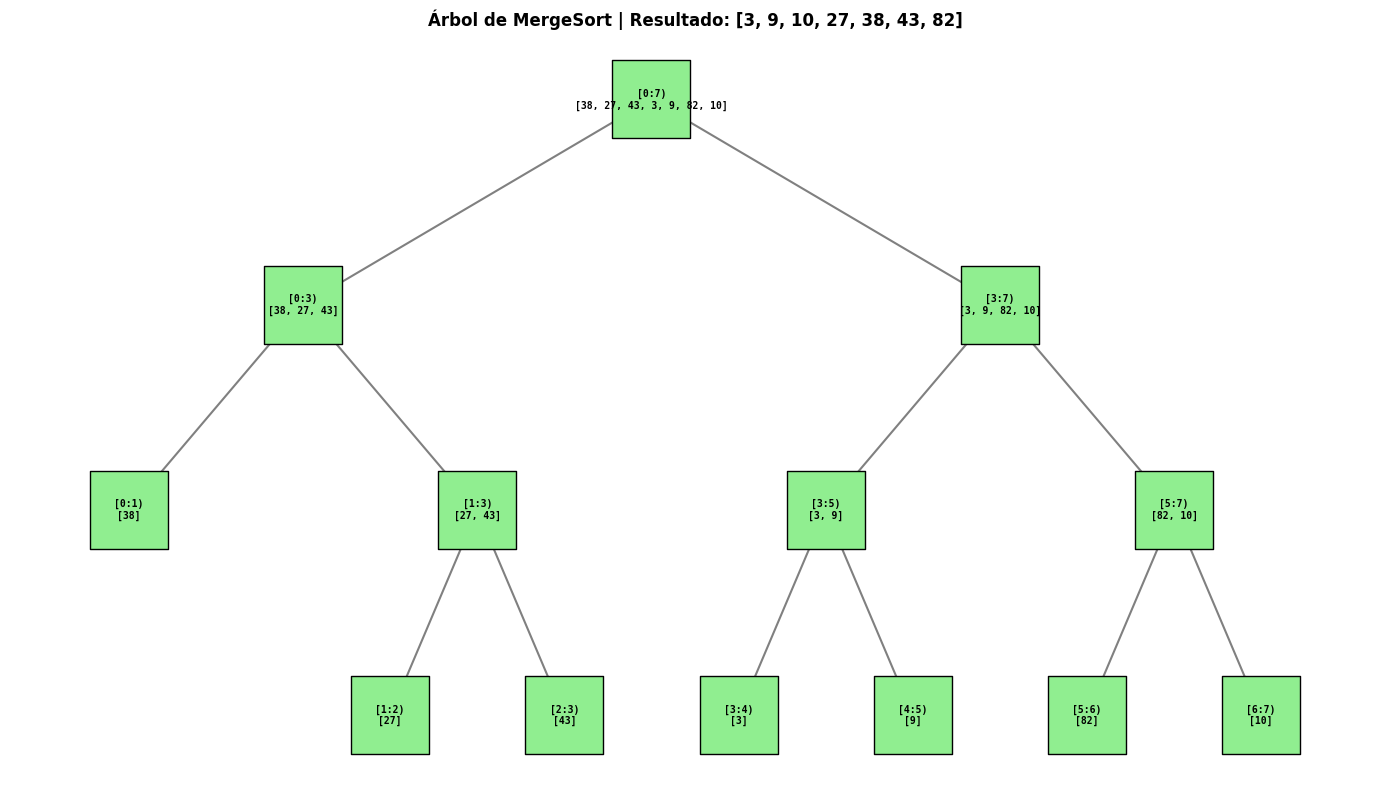


Aleatorios | n = 5000 | 10 ejecuciones por algoritmo
MergeSort: 28.697252 ms/ejecución (rango entre lotes: 22.795064–38.449382)
QuickSort primer elemento: 17.203412 ms/ejecución (rango entre lotes: 14.238069–27.843463)
QuickSort mediana de tres: 20.820828 ms/ejecución (rango entre lotes: 14.826451–37.147758)

Inversos | n = 2000 | 5 ejecuciones por algoritmo
MergeSort: 6.134186 ms/ejecución (rango entre lotes: 5.511772–6.607941)
QuickSort primer elemento: 218.432221 ms/ejecución (rango entre lotes: 158.498625–334.545334)
QuickSort mediana de tres: 2.617996 ms/ejecución (rango entre lotes: 2.495476–2.978332)

Escalamiento en datos inversos | 3 ejecuciones por tamaño y algoritmo
Algoritmo | ms a n=500 | ms a n=1000 | razón T(1000)/T(500)
MergeSort | 0.686008 | 1.461708 | 2.13×
QuickSort primer elemento | 10.437768 | 40.456676 | 3.88×
QuickSort mediana de tres | 0.700818 | 1.194454 | 1.70×


In [ ]:
# ==============================================================================
# LABORATORIO UNIDAD 2 - MERGESORT Y QUICKSORT EN PYTHON
# ==============================================================================
import sys
import timeit
import random
import matplotlib.pyplot as plt
import networkx as nx

# ------------------------------------------------------------------------------
# 1. IMPLEMENTACIÓN DE MERGESORT
# ------------------------------------------------------------------------------
def merge_sort(arr):
    if len(arr) <= 1:
        return arr

    mid = len(arr) // 2
    left = merge_sort(arr[:mid])
    right = merge_sort(arr[mid:])

    return merge(left, right)

def merge(left, right):
    result = []
    i = j = 0
    while i < len(left) and j < len(right):
        if left[i] <= right[j]:  # Preserva estabilidad
            result.append(left[i])
            i += 1
        else:
            result.append(right[j])
            j += 1
    result.extend(left[i:])
    result.extend(right[j:])
    return result

# ------------------------------------------------------------------------------
# 2. IMPLEMENTACIÓN DE QUICKSORT (PIVOTE PRIMER ELEMENTO Y MEDIANA DE 3)
# ------------------------------------------------------------------------------
def quicksort_basic(arr):
    """QuickSort básico utilizando el primer elemento (arr[0]) como pivote."""
    if len(arr) <= 1:
        return arr
    pivot = arr[0]
    less = [x for x in arr[1:] if x <= pivot]
    greater = [x for x in arr[1:] if x > pivot]
    return quicksort_basic(less) + [pivot] + quicksort_basic(greater)

def quicksort_median3(arr):
    """QuickSort optimizado con pivote Mediana de Tres."""
    if len(arr) <= 1:
        return arr

    first = arr[0]
    middle = arr[len(arr) // 2]
    last = arr[-1]

    # Elección de la mediana de los tres candidatos
    pivot = sorted([first, middle, last])[1]

    # Partición alrededor de la mediana
    arr_copy = arr.copy()
    arr_copy.remove(pivot)
    less = [x for x in arr_copy if x <= pivot]
    greater = [x for x in arr_copy if x > pivot]

    return quicksort_median3(less) + [pivot] + quicksort_median3(greater)

# ------------------------------------------------------------------------------
# 3. VISUALIZACIÓN JERÁRQUICA DEL ÁRBOL DE RECURSIÓN (MERGESORT)
# ------------------------------------------------------------------------------
def build_mergesort_tree(arr):
    graph = nx.DiGraph()

    def visitar(inicio, fin, padre=None):
        nodo = (inicio, fin)  # Intervalo [inicio, fin) único incluso con valores repetidos.
        graph.add_node(nodo, label=f"[{inicio}:{fin})\n{arr[inicio:fin]}")
        if padre is not None:
            graph.add_edge(padre, nodo)
        if fin - inicio > 1:
            medio = inicio + (fin - inicio) // 2
            visitar(inicio, medio, nodo)
            visitar(medio, fin, nodo)

    visitar(0, len(arr))
    return graph

sample_data = [38, 27, 43, 3, 9, 82, 10]
G_merge = build_mergesort_tree(sample_data)
root_merge = (0, len(sample_data))
assert describir_arbol(G_merge, root_merge) == ({0: 1, 1: 2, 2: 4, 3: 6}, {2: 1, 3: 6})
assert len(G_merge) == 13
plot_hierarchical_tree(
    G_merge, root_merge,
    f"Árbol de MergeSort | Resultado: {merge_sort(sample_data)}",
    node_color="lightgreen",
)

# Los tres algoritmos reciben exactamente los mismos datos de cada escenario.
rng = random.Random(42)
random_data = [rng.randint(1, 100000) for _ in range(5000)]
reverse_data = list(range(2000, 0, -1))
algoritmos = {
    "MergeSort": merge_sort,
    "QuickSort primer elemento": quicksort_basic,
    "QuickSort mediana de tres": quicksort_median3,
}
resultados_python = {}
limite_previo = sys.getrecursionlimit()
try:
    sys.setrecursionlimit(max(5000, limite_previo))  # Solo para reproducir el peor caso.
    for tipo, datos, repeticiones in [("Aleatorios", random_data, 10), ("Inversos", reverse_data, 5)]:
        print(f"\n{tipo} | n = {len(datos)} | {repeticiones} ejecuciones por algoritmo")
        referencia = sorted(datos)
        resultados_python[tipo] = {}
        for nombre, ordenar in algoritmos.items():
            for caso in ([], [7], [3, -2, 3, 1], [5] * 25, [1, 2, 3], datos):
                assert ordenar(caso) == (referencia if caso is datos else sorted(caso)), nombre
            medicion = medir_python(lambda: ordenar(datos), repeticiones, 1)
            resultados_python[tipo][nombre] = medicion
            mostrar_medicion(nombre, medicion)

    # Misma distribución, tamaños duplicados, para observar órdenes de crecimiento.
    print("\nEscalamiento en datos inversos | 3 ejecuciones por tamaño y algoritmo")
    print("Algoritmo | ms a n=500 | ms a n=1000 | razón T(1000)/T(500)")
    for nombre, ordenar in algoritmos.items():
        tiempos = []
        for n in (500, 1000):
            datos = list(range(n, 0, -1))
            tiempos.append(medir_python(lambda: ordenar(datos), 3, 1)[0])
        print(f"{nombre} | {tiempos[0]:.6f} | {tiempos[1]:.6f} | {tiempos[1] / tiempos[0]:.2f}×")
finally:
    sys.setrecursionlimit(limite_previo)


### 2.3 Laboratorio en C++: MergeSort con Memoria Auxiliar vs. QuickSort In-Place Optimizado

*Instrucciones:* Ejecuta las siguientes dos celdas para compilar con `g++ -O3` y comparar el rendimiento sobre $500,000$ elementos entre **MergeSort** (con reserva dinámica de vectores `L` y `R`) y **QuickSort Optimizado** (*in-place*, Mediana de Tres, inserción directa para subarreglos menores a 10 elementos y eliminación de recursión de cola).

In [ ]:
%%writefile laboratorio_mergesort_quicksort.cpp
// ==============================================================================
// LABORATORIO UNIDAD 2 - MERGESORT Y QUICKSORT EN C++
// ==============================================================================
#include <iostream>
#include <vector>
#include <chrono>
#include <algorithm>
#include <random>
#include <iomanip>

using namespace std;

// ------------------------------------------------------------------------------
// 1. MERGESORT CON MEMORIA DINÁMICA AUXILIAR
// ------------------------------------------------------------------------------
void mezclar(vector<int>& A, int ini, int med, int fin) {
    int n1 = med - ini + 1;
    int n2 = fin - med;

    vector<int> L(n1), R(n2);
    for (int i = 0; i < n1; i++) L[i] = A[ini + i];
    for (int j = 0; j < n2; j++) R[j] = A[med + 1 + j];

    int i = 0, j = 0, k = ini;
    while (i < n1 && j < n2) {
        if (L[i] <= R[j]) {
            A[k] = L[i];
            i++;
        } else {
            A[k] = R[j];
            j++;
        }
        k++;
    }
    while (i < n1) { A[k] = L[i]; i++; k++; }
    while (j < n2) { A[k] = R[j]; j++; k++; }
}

void mergeSort(vector<int>& A, int ini, int fin) {
    if (ini < fin) {
        int med = ini + (fin - ini) / 2;
        mergeSort(A, ini, med);
        mergeSort(A, med + 1, fin);
        mezclar(A, ini, med, fin);
    }
}

// ------------------------------------------------------------------------------
// 2. QUICKSORT IN-PLACE CON MEDIANA DE TRES Y OPTIMIZACIÓN DE PILA
// ------------------------------------------------------------------------------
int particionMediana3(vector<int>& A, int low, int high) {
    int mid = low + (high - low) / 2;

    // Seleccionar mediana entre low, mid, high
    if (A[mid] < A[low]) swap(A[low], A[mid]);
    if (A[high] < A[low]) swap(A[low], A[high]);
    if (A[high] < A[mid]) swap(A[mid], A[high]);

    // Colocar el pivote en high - 1 para ejecutar la partición estándar
    swap(A[mid], A[high - 1]);
    int pivot = A[high - 1];

    int i = low;
    int j = high - 1;

    for (;;) {
        while (A[++i] < pivot) {}
        while (pivot < A[--j]) {}
        if (i >= j) break;
        swap(A[i], A[j]);
    }
    swap(A[i], A[high - 1]);
    return i;
}

void quickSortOptimizado(vector<int>& A, int low, int high) {
    while (low < high) {
        // Para subarreglos pequeños (< 10), usar ordenamiento por inserción
        if (high - low + 1 < 10) {
            for (int i = low + 1; i <= high; i++) {
                int key = A[i];
                int j = i - 1;
                while (j >= low && A[j] > key) {
                    A[j + 1] = A[j];
                    j--;
                }
                A[j + 1] = key;
            }
            break;
        } else {
            int p = particionMediana3(A, low, high);

            // Optimización de Pila: Procesar recursivamente la partición menor primero
            if (p - low < high - p) {
                quickSortOptimizado(A, low, p - 1);
                low = p + 1; // Iterar sobre la partición derecha (Tail Recursion Elimination)
            } else {
                quickSortOptimizado(A, p + 1, high);
                high = p - 1; // Iterar sobre la partición izquierda
            }
        }
    }
}

int main() {
    const auto validar = [](const vector<int>& entrada) {
        auto esperado = entrada;
        sort(esperado.begin(), esperado.end());
        auto m = entrada;
        auto q = entrada;
        const int fin = static_cast<int>(entrada.size()) - 1;
        mergeSort(m, 0, fin);
        quickSortOptimizado(q, 0, fin);
        return m == esperado && q == esperado;
    };
    const vector<vector<int>> pruebas = {
        {}, {7}, {3, -2, 3, 1}, vector<int>(100, 7),
        {0, 1, 2, 3, 4, 5, 6, 7, 8}, {0, 1, 2, 3, 4, 5, 6, 7, 8, 9},
        {20, 16, 15, 13, 11, 10, 9, 8, 7, 6, 5, 4, 3, 2, 1, 0},
        {0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15}
    };
    for (const auto& caso : pruebas) {
        if (!validar(caso)) {
            cerr << "Fallo en un caso de prueba\n";
            return 1;
        }
    }

    constexpr int n = 500000;
    constexpr int corridas = 5;
    mt19937 rng(42);
    uniform_int_distribution<int> valores(0, 999999);
    vector<int> entrada(n);
    for (auto& valor : entrada) valor = valores(rng);
    auto esperado = entrada;
    sort(esperado.begin(), esperado.end());

    const auto medir = [](auto ordenar, vector<int>& datos) {
        const auto inicio = chrono::steady_clock::now();
        ordenar(datos, 0, static_cast<int>(datos.size()) - 1);
        const auto fin = chrono::steady_clock::now();
        return chrono::duration<double, milli>(fin - inicio).count();
    };
    vector<double> tm, tq;
    cout << fixed << setprecision(6);
    cout << "n = " << n << " | aleatorios, semilla 42 | C++ -O3\n";
    for (int corrida = 0; corrida < corridas; ++corrida) {
        auto m = entrada;
        auto q = entrada;
        if (corrida % 2 == 0) {
            tm.push_back(medir(mergeSort, m));
            tq.push_back(medir(quickSortOptimizado, q));
        } else {
            tq.push_back(medir(quickSortOptimizado, q));
            tm.push_back(medir(mergeSort, m));
        }
        if (m != esperado || q != esperado) {
            cerr << "Fallo de ordenamiento en la corrida " << corrida + 1 << '\n';
            return 1;
        }
        cout << "Corrida " << corrida + 1 << ": MergeSort " << tm.back()
             << " ms | QuickSort " << tq.back() << " ms\n";
    }
    sort(tm.begin(), tm.end());
    sort(tq.begin(), tq.end());
    cout << "Mediana MergeSort: " << tm[corridas / 2] << " ms | rango "
         << tm.front() << "–" << tm.back() << " ms\n";
    cout << "Mediana QuickSort: " << tq[corridas / 2] << " ms | rango "
         << tq.front() << "–" << tq.back() << " ms\n";
    cout << "Razón MergeSort / QuickSort: " << tm[corridas / 2] / tq[corridas / 2] << "×\n";
    cout << "Verificación correcta en 8 casos y 5 corridas para ambos algoritmos.\n";
    return 0;
}


Writing laboratorio_mergesort_quicksort.cpp


In [ ]:
%%bash
set -euo pipefail
g++ -O3 -std=c++17 -Wall -Wextra -Werror -pedantic laboratorio_mergesort_quicksort.cpp -o laboratorio_mq
./laboratorio_mq


n = 500000 | aleatorios, semilla 42 | C++ -O3
Corrida 1: MergeSort 100.378651 ms | QuickSort 45.603304 ms
Corrida 2: MergeSort 95.829527 ms | QuickSort 45.468268 ms
Corrida 3: MergeSort 99.391068 ms | QuickSort 45.483431 ms
Corrida 4: MergeSort 95.550638 ms | QuickSort 45.357922 ms
Corrida 5: MergeSort 94.597006 ms | QuickSort 45.364539 ms
Mediana MergeSort: 95.829527 ms | rango 94.597006–100.378651 ms
Mediana QuickSort: 45.468268 ms | rango 45.357922–45.603304 ms
Razón MergeSort / QuickSort: 2.107613×
Verificación correcta en 8 casos y 5 corridas para ambos algoritmos.


# Sección Final · Bitácora de reporte

**Nombre** Juan José Santiago Cruz · **Matrícula** 2251330013 · **Grupo** 5° K · **Fecha de entrega** 26/11/26

Mediciones de referencia obtenidas en un entorno CPU de Google Colab con Python 3.13.18 en Linux x86_64 y GCC con `-O3 -std=c++17 -Wall -Wextra -Werror -pedantic`. Las celdas imprimen sus propias mediciones al ejecutarse. Los tiempos de esta bitácora corresponden a una corrida concreta y pueden variar con la carga del entorno.

## Parte I · Fundamentos, MinMax y Potencia

### Fase 1 · Árbol de MinMax

Para `[38, 27, 43, 3, 9, 82, 10]`, el resultado es mínimo **3** y máximo **82**. Con la raíz a profundidad 0, hay **3 niveles** (0, 1 y 2), **2 nodos en el nivel 1** y **4 hojas**, todas en el nivel 2. Si se numera desde 1, el primer nivel contiene solo la raíz. Las hojas son los intervalos inclusivos `[0:1]`, `[2:3]`, `[4:5]` y `[6:6]`.

Con `mid = (low + high) // 2`, un intervalo de tamaño par genera dos hijos del mismo tamaño. Si el tamaño es impar, el hijo izquierdo recibe $\lceil n/2\rceil$ elementos y el derecho $\lfloor n/2\rfloor$. En la raíz, $7=4+3$. El 3 luego se divide en 2 y 1. El árbol de este ejemplo tiene todas las hojas a la misma profundidad aun con cargas diferentes por hoja. Para otros tamaños, como $n=5$, los casos base de uno o dos elementos pueden aparecer en niveles consecutivos.

### Fase 2 · Benchmark MinMax

| Lenguaje / reloj | Algoritmo | Tamaño | Ejecuciones | Tiempo registrado | Variación |
|---|---|---:|---:|---:|---|
| Python / `timeit` | D&C MinMax | 10 000 | 50 | 13.901618 ms/ejec. | 9.877360–18.741084 ms entre lotes |
| Python / `timeit` | Iterativo MinMax | 10 000 | 50 | 3.490095 ms/ejec. | 2.788604–4.917599 ms entre lotes |
| C++ / `chrono::steady_clock` | D&C MinMax | 1 000 000 | 1 | 2.76448 ms | Una observación |

Las versiones de Python reciben la misma lista descendente y el promedio resume cinco lotes de diez ejecuciones. La creación de la entrada, las verificaciones y el grafo quedan fuera del intervalo medido. Con estos datos, D&C tardó **3.98×** lo que tardó el iterativo, aunque ambos son $\Theta(n)$. La versión iterativa usa espacio auxiliar $\Theta(1)$ y su condición `elif` evita revisar el máximo cuando aparece un mínimo nuevo. Las filas de Python y C++ tienen tamaños distintos, por lo que sus tiempos absolutos no dan una razón de aceleración entre lenguajes para un mismo $n$.

Para un millón de elementos, el camino más largo de MinMax tiene 20 llamadas activas de MinMax contando la raíz y la hoja. Su profundidad logarítmica queda muy por debajo del límite usual de recursión de Python. El costo dominante de la versión medida es la ejecución de una cantidad lineal de llamadas y retornos en CPython, incluyendo manejo de marcos, desempaquetado de pares y operaciones con objetos. En la plantilla original también se copiaba y convertía cada subarreglo a texto aunque el grafo estuviera desactivado. Ese trabajo por nivel podía elevar el tiempo a $\Theta(n\log n)$ y se excluyó de la ruta medida. Dibujar el árbol de un millón de elementos sería otro experimento, con un costo considerable en memoria y renderización.

### Fase 3 · Potencia y pila de llamadas

Los exponentes visitados son **60 → 30 → 15 → 7 → 3 → 1 → 0**. Son seis aristas y siete llamadas contando el caso base. La función reutiliza el único resultado recursivo en cada nivel y devuelve **1 152 921 504 606 846 976** para $2^{60}$. En el modelo de multiplicación de ancho fijo y para resultados representables, el trabajo y la pila son $\Theta(\log n)$ para $n\ge2$. MinMax también usa pila $\Theta(\log n)$ porque recorre una rama a la vez, aunque en total visita $\Theta(n)$ nodos. Para un millón de datos mantiene hasta 20 marcos del algoritmo, frente a los siete de esta potencia.

## Parte II · MergeSort y QuickSort

### Fase 4 · Comparación topológica

| Árbol | Nodos por profundidad desde la raíz | Total | Hojas | Profundidad máxima |
|---|---|---:|---:|---:|
| MinMax | 1, 2, 4 | 7 | 4 | 2 |
| MergeSort | 1, 2, 4, 6 | 13 | 7 | 3 |

En el MergeSort de Python, `mid = len(arr) // 2` deja 3 elementos a la izquierda y 4 a la derecha. La recursión sigue hasta tamaños de uno. Hay una hoja a profundidad 2 y seis a profundidad 3. Cada nodo interno tiene dos hijos, así que con siete hojas hay $2\cdot7-1=13$ nodos. MinMax resuelve cada par en el caso base con una comparación. Si se expandieran sus tres hojas de tamaño dos, se obtendrían seis nodos adicionales. El orden de las mitades en el dibujo sigue el recorrido real de cada implementación.

### Fase 5 · Pivote y peor caso en Python

Promedios en ms por ejecución. Las entradas aleatorias utilizan semilla 42. Dentro de cada escenario se usan los mismos datos para los tres algoritmos. La preparación y la verificación contra `sorted` quedan fuera de la medición.

| Algoritmo | Aleatorios, 5 000 (10 corridas) | Inversos, 2 000 (5 corridas) | Cota teórica y razón observada en la prueba de escala inversa |
|---|---:|---:|---|
| MergeSort | 28.697252 | 6.134186 | $\Theta(n\log n)$, razón 2.13× al duplicar de 500 a 1 000 |
| QuickSort, primer elemento | 17.203412 | 218.432221 | $\Theta(n^2)$ en inversos, razón 3.88× |
| QuickSort, mediana de tres | 20.820828 | 2.617996 | $\Theta(n\log n)$ para esta familia inversa, razón 1.70× |

En la lista inversa de claves distintas, el primer pivote es siempre el máximo y deja un problema de tamaño $m-1$ y otro de tamaño 0. La rama larga llega a unas 2 000 llamadas activas, por lo que se eleva localmente el límite a 5 000 y se restaura mediante `finally`. Cada nivel vuelve a recorrer y copiar referencias. La suma $\sum_{m=2}^{n}(m-1)=n(n-1)/2$ explica el trabajo cuadrático. Las listas retenidas por las llamadas activas también pueden sumar $\Theta(n^2)$ referencias en esta versión Python.

Con primero, centro y último en una lista monótona de claves distintas, la mediana de tres elige la clave central y las comprensiones conservan el orden relativo de cada partición. En este escenario fue **83.43×** más rápido que el pivote inicial para el mismo $n=2000$. En el aleatorio de $n=5000$, la variante con mediana hizo trabajo adicional al seleccionar y retirar el pivote y su promedio fue mayor. El peor caso cuadrático sigue siendo posible con otras entradas, como una lista de claves iguales para esta partición Python de dos grupos. Al duplicar el tamaño, el tiempo del pivote inicial se acercó al factor 4 del crecimiento cuadrático. MergeSort y la mediana de tres crecieron menos en este intervalo. Dos tamaños y unas pocas corridas muestran una tendencia. La clasificación asintótica se deriva de las recurrencias.

### Fase 6 · Tiempo, memoria y pila en C++

Ambos algoritmos ordenaron copias del mismo vector de 500 000 enteros pseudoaleatorios (semilla 42). Se alternó el orden de ejecución, se excluyeron la generación y la copia inicial y se comparó cada salida con `std::sort` fuera del cronómetro. Las asignaciones propias de MergeSort sí se miden.

| Algoritmo C++ | Tamaño | Corridas | Mediana (ms) | Mín.–máx. (ms) | Espacio auxiliar |
|---|---:|---:|---:|---:|---|
| MergeSort con vectores L y R | 500 000 | 5 | 95.829527 | 94.597006–100.378651 | $\Theta(n)$ en buffers y $O(\log n)$ en pila |
| QuickSort optimizado | 500 000 | 5 | 45.468268 | 45.357922–45.603304 | $O(\log n)$ en pila, $O(1)$ por partición |

La mediana de MergeSort fue **2.11×** la de QuickSort. Las mezclas de MergeSort recorren secuencialmente sus vectores, lo que favorece la localidad espacial. Cada mezcla también reserva y libera L y R, copia los elementos a los temporales y escribe el intervalo de vuelta. Esto aumenta el tráfico de memoria y el conjunto de datos activo. QuickSort particiona dentro del mismo vector, usando dos recorridos que avanzan desde los extremos. El ciclo procesa el tramo mayor en el mismo marco y la inserción directa evita particionar tramos de menos de diez elementos. El menor tramo tiene a lo sumo $\lfloor(m-1)/2\rfloor$ elementos, de modo que los marcos activos decrecen geométricamente. La cota de pila vale incluso cuando el tiempo de particionar es cuadrático. Estos mecanismos explican la diferencia observada como hipótesis de implementación. El experimento midió tiempo de pared, sin contadores de caché ni aislamiento del efecto de cada optimización.


### Formato de Entrega / Portafolio de Evidencias
1. Guarda este cuaderno con todas las salidas ejecutadas incluyendo las respuesta a las preguntas (`Archivo` -> `Guardar una copia en Drive`).
2. Sube los cambios a tu repositorio de GitHub de la materia bajo el nombre `JUAN PEREZ laboratorio_divide_y_venceras.ipynb` usando la integración directa (`Archivo` -> `Guardar una copia en GitHub`).
3. Adjunta en tu entregable de plataforma Moodle, el enlace de GitHub.